# Análisis gráfico de reacciones de alcanos, alquenos y cicloalquenos

**Proyecto final · Química Orgánica · Ingeniería Ambiental · UDFJC · 2026-III**
**Integrantes:** _(completar)_ · **Repositorio:** _(completar)_ · **Fuente de datos:** tabla `Datos_Reacciones` (CAS SciFinder)

---

## 0. Cómo leer y ejecutar este cuaderno

Este cuaderno está escrito para poder **explicarse y modificarse en vivo**. Por eso cada bloque de código viene precedido de una celda Markdown que dice **qué se hace, por qué se hace y cómo se cambia**, y cada gráfica viene seguida de una **interpretación**.

**Para ejecutarlo en Google Colab**

1. Sube este `.ipynb` a Colab (Archivo → Subir cuaderno).
2. Ejecuta todo con *Entorno de ejecución → Ejecutar todo*. Cuando llegue a la celda 2 te pedirá el archivo: sube `Datos_Reacciones.xlsx`.
3. Las figuras se guardan solas en la carpeta `figuras/` (para pegarlas luego en el informe de LaTeX).

**Para ejecutarlo en Jupyter/Anaconda:** deja `Datos_Reacciones.xlsx` en la misma carpeta que el cuaderno y ejecuta todo.

### Estructura (siguiendo el orden que pide el análisis)

| Parte | Qué contiene |
|---|---|
| 1 | Carga, limpieza, clasificación y codificación de variables |
| 2 | Estadística descriptiva (frecuencias y distribución) |
| 3 | **Mapas de calor primero** (Spearman, V de Cramér y razón de correlación η) para detectar correlaciones posibles |
| 4 | **Gráficas que evidencian** cada correlación detectada (tendencia y probabilidad) |
| 5 | Comportamientos anómalos (valores atípicos) |
| 6 | Contraste de las hipótesis de partida |
| 7 | Conclusiones |
| 8 | Guía para modificar las gráficas en vivo (sustentación) |

> **Nota:** las interpretaciones escritas debajo de cada gráfica citan los valores de la versión actual de la tabla. Si se corrige algún dato al contrastar con SciFinder, hay que volver a ejecutar el cuaderno y actualizar los números citados en esos textos.

### Hipótesis de partida (el "plan" antes de analizar)

Analizar datos es una operación consciente: primero se plantea qué se espera encontrar y luego se contrasta con los datos.

- **H1 (propiedades físicas):** el peso molecular controla las fuerzas de dispersión de London; por tanto, a mayor PM debe subir el punto de ebullición y bajar la presión de vapor.
- **H2 (química de la reacción):** el tipo de reacción no es independiente del medio ni del catalizador (por ejemplo, las eliminaciones E1/E2 ocurren en medio ácido o básico, y las sustituciones radicalarias en medio apolar con luz UV).
- **H3 (energía de activación):** la temperatura de reacción depende de la familia de reacción y del catalizador (la combustión y el craqueo necesitan temperaturas altas; las adiciones catalizadas, bajas).
- **H4 (dirección de la consulta):** las **reacciones** (el alcano/alqueno como reactante) y las **obtenciones** (como producto) no usan las mismas condiciones.

## 1. Preparación del entorno, carga y limpieza de datos

### 1.1 Librerías y funciones de apoyo

**Qué hace la celda siguiente**

- `import ... as ...` carga una librería y le da un apodo corto:
  - `pandas (pd)`: manejo de tablas (DataFrame). Es el "Excel" de Python.
  - `numpy (np)`: matemáticas sobre arreglos y manejo de valores vacíos (`np.nan`).
  - `matplotlib.pyplot (plt)`: base de todas las gráficas.
  - `seaborn (sns)`: gráficas estadísticas bonitas construidas sobre matplotlib.
  - `scipy.stats (stats)`: pruebas estadísticas (Spearman, chi-cuadrado, Kruskal-Wallis, Mann-Whitney).
- `sns.set_theme(...)` fija un estilo único para **todas** las gráficas. Si quieres otro estilo en vivo, cambia `style='whitegrid'` por `'darkgrid'`, `'white'` o `'ticks'`, y la paleta `'colorblind'` por `'Set2'`, `'viridis'`, etc.
- `plt.rcParams.update({...})` cambia parámetros globales: resolución en pantalla (`figure.dpi`), resolución al guardar (`savefig.dpi`, 300 es calidad de impresión) y negrilla en los títulos.
- `guardar(nombre)` es una función propia: guarda la figura activa en `figuras/nombre.png`. La llamamos antes de `plt.show()` porque después de `show()` la figura se borra.

In [1]:
# ---- Librerías ----
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ---- Estilo global de las gráficas ----
warnings.filterwarnings('ignore')                  # oculta avisos menores para que la salida quede limpia
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({
    'figure.dpi': 110,        # resolución en pantalla
    'savefig.dpi': 300,       # resolución al guardar (calidad informe)
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
})

# ---- Carpeta donde se guardarán las figuras para el informe LaTeX ----
os.makedirs('figuras', exist_ok=True)

def guardar(nombre):
    # Guarda la figura activa como PNG. bbox_inches='tight' evita que se corten las etiquetas.
    plt.savefig(os.path.join('figuras', nombre + '.png'), bbox_inches='tight')

# ---- Etiquetas legibles (con unidades) para los ejes ----
ETIQ = {
    'T_rxn':   'Temperatura de reacción (°C)',
    'PM':      'Peso molecular (g/mol)',
    'Tf':      'Punto de fusión (°C)',
    'Teb':     'Punto de ebullición (°C)',
    'densidad':'Densidad (g/cm³)',
    'mu':      'Momento dipolar (D)',
    'solub_gL':'Solubilidad en agua (g/L)',
    'Pvap':    'Presión de vapor (mmHg)',
    'Pvap_log':'log10 de la presión de vapor (mmHg)',
    'pKa':     'pKa',
    'dPM':     'Δ peso molecular (g/mol)',
}
ETIQ_CORTA = {'T_rxn':'T reacción','PM':'PM','Tf':'T fusión','Teb':'T ebullición','densidad':'Densidad',
              'mu':'Momento dipolar','solub_gL':'Solubilidad','Pvap':'P vapor'}
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


### 1.2 Carga del archivo Excel

La función `localizar_excel()` busca en la carpeta actual un archivo que empiece por `datos_reacciones` y termine en `.xlsx`; si no lo encuentra y estamos en Colab, abre el cuadro para subirlo (`files.upload()`).

`pd.read_excel(ruta, sheet_name='Reacciones')` lee una hoja del libro. Usamos dos:

- **`Reacciones`**: las 200 filas del proyecto (10 sustancias × 10 reacciones + 10 obtenciones).
- **`Sustancias`**: propiedades de cada sustancia, que usaremos para calcular cuánto cambia una propiedad entre la sustancia consultada y la asociada. `header=1` indica que los nombres de las columnas están en la **segunda** fila (la primera es un título).

In [2]:
def localizar_excel():
    # 1) Busca el archivo en la carpeta actual (sin importar mayúsculas/minúsculas)
    archivos = [f for f in os.listdir('.')
                if f.lower().startswith('datos_reacciones') and f.lower().endswith('.xlsx')]
    if archivos:
        return archivos[0]
    # 2) Si estamos en Colab, pide subirlo
    try:
        from google.colab import files
        print('Sube el archivo Datos_Reacciones.xlsx')
        subidos = files.upload()
        return list(subidos.keys())[0]
    except ImportError:
        raise FileNotFoundError('Coloca Datos_Reacciones.xlsx en la misma carpeta que este cuaderno.')

RUTA = localizar_excel()
raw  = pd.read_excel(RUTA, sheet_name='Reacciones')           # tabla principal (200 filas)
sust = pd.read_excel(RUTA, sheet_name='Sustancias', header=1)  # propiedades por sustancia

print('Archivo:', RUTA)
print('Hoja Reacciones :', raw.shape, '(filas, columnas)')
print('Hoja Sustancias :', sust.shape)
raw.head(3)

Archivo: Datos_Reacciones.xlsx
Hoja Reacciones : (200, 22) (filas, columnas)
Hoja Sustancias : (145, 10)


,ID,Sustancia consultada,Tipo de consulta,N°,Reactivo(s),Catalizador(es),Solvente(s),Temperatura de reacción (°C),Medio,Producto(s),...,Sustancia asociada (producto principal / reactante),Peso molecular (g/mol),Punto de fusión (°C),Punto de ebullición (°C),Densidad (g/cm³),pKa,Momento dipolar (D),Solubilidad en agua (g/L),Presión de vapor (mmHg),Observación
0,R001,pentano,Reacción,1,pentano + O2 (exceso),Ninguno (ignición),Ninguno (fase gas),800,Neutro,CO2 + H2O,...,dióxido de carbono,44.01,-78.5,-,1.562,6.35,0.00,1.45,56500,Reacción exotérmica; productos únicos CO2 y H2...
1,R002,pentano,Reacción,2,pentano + O2 (limitado),Ninguno (ignición),Ninguno (fase gas),600,Neutro,CO + H2O,...,monóxido de carbono,28.01,-205.0,-191.5,0.789,-,0.11,0.028,760,O2 limitado favorece CO sobre CO2; proporción ...
2,R003,pentano,Reacción,3,pentano + Cl2,Luz UV (hν),Ninguno (fase líquida),25,Apolar,2-cloropentano + HCl,...,2-cloropentano,106.60,-137.0,97,0.869,-,2.16,0.6,32,Mezcla de isómeros monoclorados


### 1.3 Primer vistazo: ¿qué trae la tabla?

`raw.info()` muestra cada columna, cuántos datos no vacíos tiene y su tipo. **Aquí aparece el primer problema:** columnas que deberían ser numéricas (`Punto de ebullición`, `pKa`, `Solubilidad`, `Presión de vapor`) aparecen como `object` (texto). La causa es que, cuando un dato no existe, la tabla tiene un guion `'-'`, y la solubilidad a veces dice `Miscible` o `Soluble` en vez de un número. Pandas, al ver un texto en una columna, la trata completa como texto.

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 22 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   ID                                                   200 non-null    str    
 1   Sustancia consultada                                 200 non-null    str    
 2   Tipo de consulta                                     200 non-null    str    
 3   N°                                                   200 non-null    int64  
 4   Reactivo(s)                                          200 non-null    str    
 5   Catalizador(es)                                      200 non-null    str    
 6   Solvente(s)                                          200 non-null    str    
 7   Temperatura de reacción (°C)                         200 non-null    int64  
 8   Medio                                                200 non-null    str    
 9  

### 1.4 Limpieza

Limpiar es dejar los datos en un formato con el que se pueda calcular. Los pasos, en orden:

1. **Renombrar columnas** con nombres cortos (`T_rxn`, `PM`, `Teb`...). Es más cómodo escribir `df['PM']` que `df['Peso molecular (g/mol)']`. El diccionario `RENOMBRAR` va de "nombre original" a "nombre nuevo".
2. **Reemplazar `'-'` por `np.nan`** (valor vacío real). Así pandas sabe que el dato falta y lo ignora al calcular.
3. **Convertir a número** con `pd.to_numeric(..., errors='coerce')`: lo que no se pueda convertir queda como vacío en vez de dar error.
4. **Tratar la solubilidad por separado:** tiene números (g/L) y también palabras (`Miscible`, `Soluble`). Se crean dos columnas: `solub_gL` (solo el número) y `solub_texto` (solo la palabra), y más adelante se construye una clase ordinal que integra ambas.
5. **Quitar espacios sobrantes** en los textos con `.str.strip()` para que `'Ácido '` y `'Ácido'` no cuenten como categorías distintas.

In [4]:
RENOMBRAR = {
    'Sustancia consultada': 'sustancia',
    'Tipo de consulta': 'consulta',
    'Reactivo(s)': 'reactivos',
    'Catalizador(es)': 'catalizador',
    'Solvente(s)': 'solvente',
    'Temperatura de reacción (°C)': 'T_rxn',
    'Medio': 'medio',
    'Producto(s)': 'productos',
    'Nombre de la reacción': 'nombre_rxn',
    'Tipo de reacción': 'tipo_rxn',
    'Sustancia asociada (producto principal / reactante)': 'asociada',
    'Peso molecular (g/mol)': 'PM',
    'Punto de fusión (°C)': 'Tf',
    'Punto de ebullición (°C)': 'Teb',
    'Densidad (g/cm³)': 'densidad',
    'Momento dipolar (D)': 'mu',
    'Solubilidad en agua (g/L)': 'solubilidad',
    'Presión de vapor (mmHg)': 'Pvap',
    'Observación': 'observacion',
}

df = raw.rename(columns=RENOMBRAR).copy()   # .copy() evita modificar el DataFrame original

# 1) Quitar espacios sobrantes en todas las columnas de texto
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('object').where(df[col].isna(), df[col].astype(str).str.strip())

# 2) El guion '-' significa "dato no disponible": lo convertimos en vacío real (NaN)
df = df.replace('-', np.nan)

# 3) Solubilidad: separar el número (g/L) de la palabra (Miscible / Soluble)
df['solub_texto'] = df['solubilidad'].where(df['solubilidad'].isin(['Miscible', 'Soluble']))
df['solub_gL']    = pd.to_numeric(df['solubilidad'], errors='coerce')

# 4) Convertir a número las columnas que quedaron como texto por culpa del '-'
for col in ['Teb', 'pKa', 'Pvap']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

NUM_BASE = ['T_rxn', 'PM', 'Tf', 'Teb', 'densidad', 'mu', 'solub_gL', 'Pvap', 'pKa']
print(df[NUM_BASE].dtypes)

T_rxn         int64
PM          float64
Tf          float64
Teb         float64
densidad    float64
mu          float64
solub_gL    float64
Pvap        float64
pKa         float64
dtype: object

### 1.5 Datos faltantes

Antes de graficar hay que saber **cuántos datos faltan en cada variable**, porque una variable con muchos vacíos produce correlaciones poco confiables.

- `df.isna()` devuelve una tabla de verdadero/falso (`True` = vacío).
- `.sum()` cuenta los vacíos por columna y `.mean()*100` los convierte a porcentaje.

**Interpretación.** Solo el **pKa** tiene un problema serio: 143 de 200 filas (71,5 %) están vacías, porque la mayoría de las sustancias asociadas (alcanos, alquenos, haluros, alcoholes) no tienen un pKa útil en agua. Con solo 57 datos no es confiable correlacionarlo con otras variables, así que **se excluye de los mapas de calor** (queda en la tabla). Las demás variables tienen pocos vacíos: punto de ebullición 8 % (16 filas), solubilidad 11 % (22) y presión de vapor 5,5 % (11). Esos vacíos no son errores: son propiedades que no existen (el CO₂ sublima, las sales de sodio se descomponen antes de hervir). **No se rellenan con cero**, porque un cero sería un dato falso; pandas simplemente los omite en cada cálculo.

In [5]:
faltantes = pd.DataFrame({
    'n_vacios': df[NUM_BASE].isna().sum(),
    '% vacíos': (df[NUM_BASE].isna().mean() * 100).round(1),
    'n_datos':  df[NUM_BASE].notna().sum(),
})
faltantes.insert(0, 'variable', faltantes.index.map(lambda c: ETIQ.get(c, c)))
faltantes.reset_index(drop=True)

,variable,n_vacios,% vacíos,n_datos
0,Temperatura de reacción (°C),0,0.0,200
1,Peso molecular (g/mol),0,0.0,200
2,Punto de fusión (°C),0,0.0,200
3,Punto de ebullición (°C),16,8.0,184
4,Densidad (g/cm³),0,0.0,200
5,Momento dipolar (D),0,0.0,200
6,Solubilidad en agua (g/L),22,11.0,178
7,Presión de vapor (mmHg),11,5.5,189
8,pKa,143,71.5,57


### 1.6 Clasificación de variables y construcción de variables categóricas agrupadas

**Primer paso para explicar tendencias: clasificar las variables.** Se separan en:

| Tipo | Variables | Cómo se analizan |
|---|---|---|
| **Categóricas nominales** (sin orden) | sustancia, clase de sustancia, tipo de consulta, medio, familia de reacción, categoría de catalizador, categoría de solvente | Frecuencias, tablas de contingencia, **V de Cramér** |
| **Categóricas ordinales** (con orden) | rango de temperatura, clase de solubilidad | Frecuencias y correlación de rangos |
| **Numéricas continuas** | T de reacción, PM, T de fusión, T de ebullición, densidad, momento dipolar, solubilidad (g/L), presión de vapor, pKa | Distribuciones, correlación de **Spearman** y regresión |

**Por qué agrupar.** La tabla trae demasiados valores distintos en algunas columnas (45 `tipo_rxn`, 35 `catalizador`, 22 `solvente`). Una prueba de asociación con tantas categorías y solo 200 filas queda con celdas casi vacías y deja de ser confiable. Se agrupan con **funciones de reglas** (`if` sobre palabras clave) y las reglas quedan visibles para poder defenderlas:

- `familia_reaccion(texto)`: lee `tipo_rxn` y devuelve una familia amplia. **El orden de las reglas importa**: la primera que se cumple gana. Por ejemplo, "Adición (syn) + oxidación" es una hidroboración-oxidación, así que la regla de *oxidación* va antes que la de *adición*; y "Sustitución nucleofílica (reducción)" es una sustitución (SN2 con hidruro), así que *sustitución* va antes que *reducción*.
- `cat_catalizador(texto)`: agrupa catalizadores por su naturaleza química (ácido, base, metal soportado, organometálico, radicalario, sin catalizador).
- `cat_solvente(texto)`: agrupa solventes por polaridad (apolar, polar prótico, polar aprótico, sin solvente).
- `pd.cut(...)`: parte una variable numérica en intervalos. Con `bins=[-inf, 0, 40, 150, 400, inf]` se crean cinco rangos de temperatura y `right=False` hace que cada intervalo incluya su límite izquierdo (el 0 queda en "Ambiente", no en "Subambiente").
- `clasificar_solub(num, texto)`: convierte la solubilidad (número o palabra) en una escala ordenada: *Muy baja* (< 0,1 g/L), *Baja* (0,1–1), *Moderada* (1–10), *Alta* (> 10 g/L o "Soluble") y *Miscible*.

In [6]:
# ---------- Familia de reacción (el orden de las reglas importa: gana la primera que se cumple) ----------
def familia_reaccion(texto):
    t = str(texto).lower()
    if 'isomeriz' in t:                                              return 'Isomerización'
    if 'cicl' in t or 'cícl' in t:                                   return 'Ciclación / pericíclica'
    if 'eliminación' in t or 'descarboxilación' in t:                return 'Eliminación'
    if 'sustitución' in t:                                           return 'Sustitución'
    if 'oxid' in t or 'combust' in t or 'epox' in t:                 return 'Oxidación'
    if 'reducción' in t:                                             return 'Reducción / hidrogenación'
    if 'hidrogenólisis' in t or 'craqueo' in t or 'ruptura' in t:    return 'Hidrogenólisis / craqueo'
    if 'adición' in t:                                               return 'Adición'
    if any(k in t for k in ['acoplamiento', 'metátesis', 'condensación', 'oligomer']):
                                                                     return 'Acoplamiento / metátesis / condensación'
    return 'Otra'

# ---------- Categoría de catalizador ----------
def cat_catalizador(texto):
    t = str(texto).lower()
    if t.startswith('ninguno'):                                      return 'Sin catalizador'
    if any(k in t for k in ['luz uv', 'aibn', 'peróxido']):          return 'Radicalario (luz / iniciador)'
    if any(k in t for k in ['h2so4', 'h3po4', 'alcl3']):             return 'Ácido'
    if any(k in t for k in ['cao', 't-buok']):                       return 'Base'
    if any(k in t for k in ['grubbs', 'rh/pph3', 'cr(iii)', 'cui', 'zn–cu', 'oso4']):
                                                                     return 'Organometálico / metal homogéneo'
    if any(k in t for k in ['pd', 'pt', 'ni/', 'níquel', 'cr2o3']):  return 'Metal soportado (heterogéneo)'
    if any(k in t for k in ['zeolita', 'al2o3']):                    return 'Sólido ácido (zeolita / alúmina)'
    return 'Otro'

# ---------- Categoría de solvente (por polaridad) ----------
def cat_solvente(texto):
    t = str(texto).lower()
    if t.startswith('ninguno'):                                      return 'Sin solvente'
    if any(k in t for k in ['ccl4', 'benceno', 'hexano', 'tolueno', 'ciclohexano', 'aceite mineral']):
                                                                     return 'Apolar'
    if any(k in t for k in ['etanol', 'ácido acético', 'agua', 't-butanol', 'dietilenglicol', 'hcl']):
                                                                     return 'Polar prótico'
    return 'Polar aprótico'

# ---------- Clase de solubilidad (escala ordinal) ----------
def clasificar_solub(num, texto):
    if texto == 'Miscible':  return 'Miscible'
    if texto == 'Soluble':   return 'Alta'
    if pd.isna(num):         return np.nan
    if num < 0.1:            return 'Muy baja'
    if num < 1:              return 'Baja'
    if num < 10:             return 'Moderada'
    return 'Alta'

# ---------- Clase de la sustancia consultada ----------
CLASE_CONS = {'pentano':'Alcano', 'isopentano':'Alcano', 'hexano':'Alcano', 'heptano':'Alcano', 'octano':'Alcano',
              'pent-2-eno':'Alqueno', '2-metilpent-2-eno':'Alqueno', 'hex-1-eno':'Alqueno',
              'ciclopropeno':'Cicloalqueno', 'ciclobuteno':'Cicloalqueno'}

# ---------- Aplicar las funciones: .apply() ejecuta la función fila a fila sobre la columna ----------
df['familia_rxn']     = df['tipo_rxn'].apply(familia_reaccion)
df['cat_catalizador'] = df['catalizador'].apply(cat_catalizador)
df['cat_solvente']    = df['solvente'].apply(cat_solvente)
df['clase_cons']      = df['sustancia'].map(CLASE_CONS)        # .map() usa el diccionario como "tabla de equivalencias"
df['solub_clase']     = [clasificar_solub(n, t) for n, t in zip(df['solub_gL'], df['solub_texto'])]

# ---------- Rango de temperatura con pd.cut ----------
ORD_T = ['Subambiente (<0 °C)', 'Ambiente (0–39 °C)', 'Moderada (40–149 °C)', 'Alta (150–399 °C)', 'Muy alta (≥400 °C)']
df['rango_T'] = pd.cut(df['T_rxn'], bins=[-np.inf, 0, 40, 150, 400, np.inf], labels=ORD_T, right=False)

# ---------- Variables numéricas derivadas ----------
props = sust[sust['Rol'] == 'Consultada'].set_index('Sustancia')               # propiedades de las 10 sustancias consultadas
df['PM_cons'] = df['sustancia'].map(props['Peso molecular (g/mol)'])
df['dPM']     = df['PM'] - df['PM_cons']                                         # cuánto cambia el PM entre consultada y asociada
df['Pvap_log'] = np.log10(df['Pvap'])                                            # log10 porque la presión de vapor abarca varios órdenes de magnitud

# ---------- Ordenes de las categorías ordinales ----------
ORD_SOL = ['Muy baja', 'Baja', 'Moderada', 'Alta', 'Miscible']
df['solub_clase'] = pd.Categorical(df['solub_clase'], categories=ORD_SOL, ordered=True)

# Comprobación: ninguna fila debe haber caído en 'Otra' / 'Otro'
for c in ['familia_rxn', 'cat_catalizador', 'cat_solvente']:
    print(f'{c:18s} →', df[c].nunique(), 'categorías;',
          'filas sin clasificar:', df[c].isin(['Otra', 'Otro']).sum())

familia_rxn        → 9 categorías; filas sin clasificar: 0
cat_catalizador    → 7 categorías; filas sin clasificar: 0
cat_solvente       → 4 categorías; filas sin clasificar: 0


### 1.7 Codificación de las variables categóricas

Los algoritmos y varias pruebas estadísticas necesitan **números**, no texto. **Codificar** es asignar a cada categoría un código entero.

- `astype('category')` declara que la columna es categórica; `.cat.codes` devuelve el código de cada fila (0, 1, 2, ...). Los vacíos reciben `-1`, que se reemplaza por `NaN`.
- Para las **ordinales** (`rango_T`, `solub_clase`) el orden de los códigos respeta el orden natural (0 = temperatura más baja). Para las **nominales** el número es solo una etiqueta: no significa que la categoría 3 sea "mayor" que la 1. Por eso las asociaciones entre nominales **no** se calculan con estos códigos sino con la **V de Cramér**, que parte de la tabla de contingencia.
- El diccionario `CODIGOS` guarda la equivalencia código → categoría (es la "leyenda" para poder interpretar luego).
- `pd.get_dummies(...)` hace la codificación *one-hot* (una columna 0/1 por categoría); se muestra para el medio de reacción como ejemplo.

In [7]:
CAT_COLS = ['sustancia', 'clase_cons', 'consulta', 'medio', 'familia_rxn',
            'cat_catalizador', 'cat_solvente', 'rango_T', 'solub_clase']

CODIGOS = {}                                                  # leyenda código → categoría
for c in CAT_COLS:
    cat = df[c].astype('category')                            # declarar categórica
    df[c + '_cod'] = cat.cat.codes.replace(-1, np.nan)        # -1 = vacío → NaN
    CODIGOS[c] = dict(enumerate(cat.cat.categories))

# Mostrar la leyenda de dos variables como ejemplo
for c in ['medio', 'rango_T']:
    print(c, '→', CODIGOS[c])

# Ejemplo de codificación one-hot del medio de reacción
pd.get_dummies(df['medio'], prefix='medio').astype(int).head()

medio → {0: 'Apolar', 1: 'Básico', 2: 'Neutro', 3: 'Ácido'}
rango_T → {0: 'Subambiente (<0 °C)', 1: 'Ambiente (0–39 °C)', 2: 'Moderada (40–149 °C)', 3: 'Alta (150–399 °C)', 4: 'Muy alta (≥400 °C)'}


,medio_Apolar,medio_Básico,medio_Neutro,medio_Ácido
0,0,0,1,0
1,0,0,1,0
2,1,0,0,0
3,1,0,0,0
4,0,0,0,1


## 2. Estadística descriptiva

### 2.1 Frecuencias de las variables categóricas

Para una variable categórica, **la frecuencia relativa es una estimación de la probabilidad**: si el 33 % de las filas tiene medio neutro, la probabilidad de que una reacción elegida al azar sea en medio neutro es aproximadamente 0,33.

`df[c].value_counts()` cuenta las filas por categoría y `normalize=True` entrega la proporción. La gráfica es un **gráfico de barras horizontal**, la opción recomendada para comparar categorías con nombres largos. `sns.countplot` cuenta y dibuja en un solo paso; `order=` lo ordena de mayor a menor.

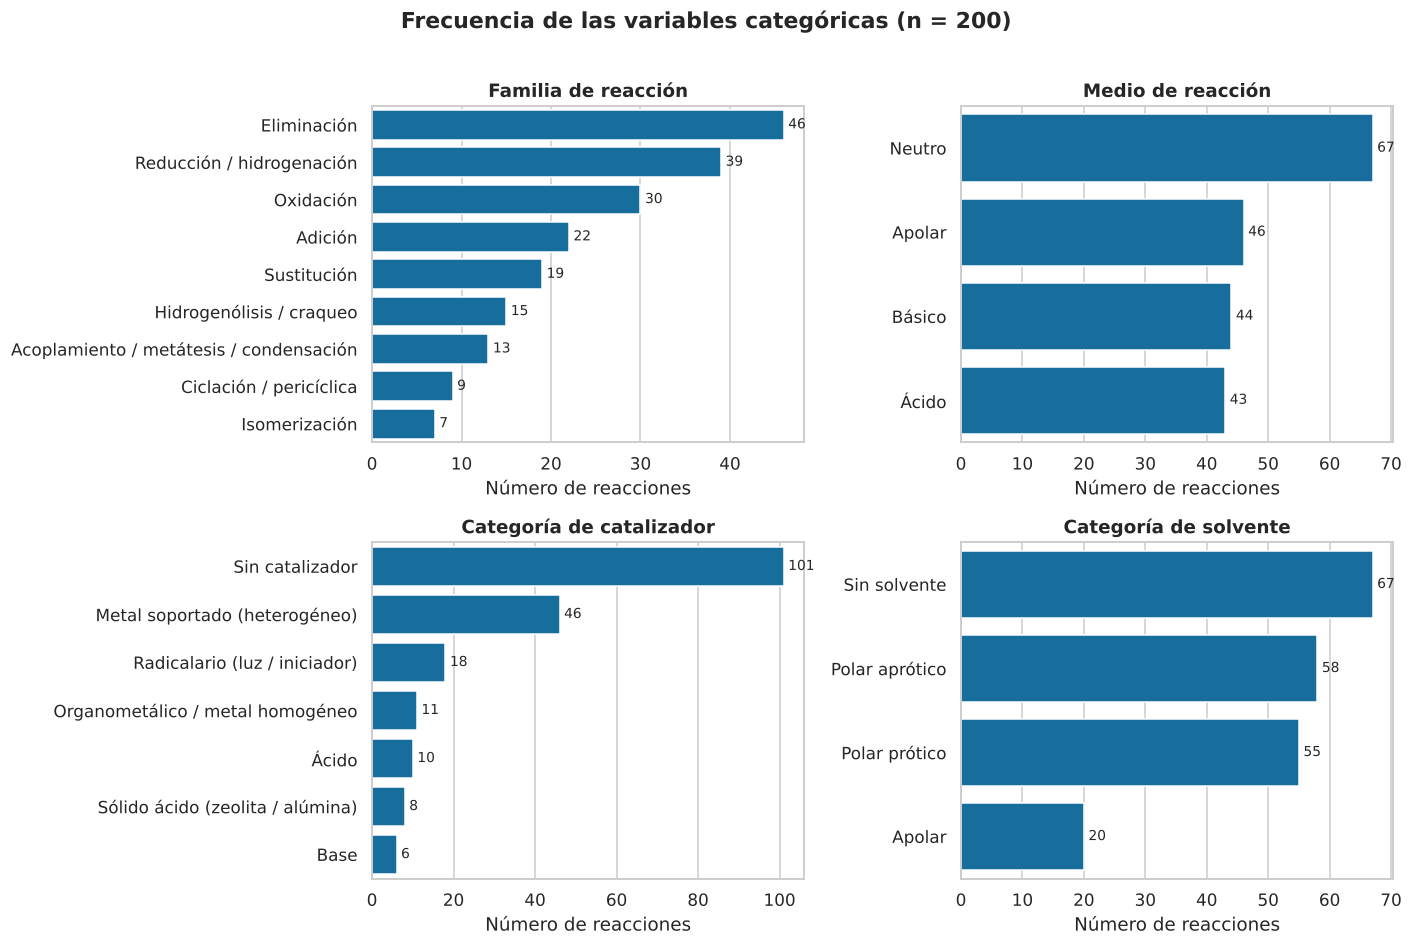

medio       Neutro          0.335
            Apolar          0.230
            Básico          0.220
            Ácido           0.215
consulta    Reacción        0.500
            Obtención       0.500
clase_cons  Alcano          0.500
            Alqueno         0.300
            Cicloalqueno    0.200
Name: proportion, dtype: float64

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
vars_freq = [('familia_rxn', 'Familia de reacción'), ('medio', 'Medio de reacción'),
             ('cat_catalizador', 'Categoría de catalizador'), ('cat_solvente', 'Categoría de solvente')]

for ax, (col, titulo) in zip(axes.ravel(), vars_freq):
    orden = df[col].value_counts().index                      # categorías de la más a la menos frecuente
    sns.countplot(data=df, y=col, order=orden, ax=ax, color=sns.color_palette()[0])
    ax.set(title=titulo, xlabel='Número de reacciones', ylabel='')
    for p in ax.patches:                                      # escribir el conteo al final de cada barra
        ax.annotate(int(p.get_width()), (p.get_width(), p.get_y() + p.get_height() / 2),
                    xytext=(3, 0), textcoords='offset points', va='center', fontsize=9)

plt.suptitle('Frecuencia de las variables categóricas (n = 200)', fontweight='bold', y=1.01)
plt.tight_layout(); guardar('01_frecuencias_categoricas'); plt.show()

# Tabla de probabilidades marginales para el informe
tabla_prob = pd.concat({c: df[c].value_counts(normalize=True).round(3) for c in ['medio', 'consulta', 'clase_cons']})
tabla_prob

**Interpretación.** Las categorías están razonablemente repartidas, lo que permite compararlas. El medio más frecuente es el **neutro** (33,5 %), seguido de apolar (23 %), básico (22 %) y ácido (21,5 %). La familia más común es la **eliminación** (46 de 200, 23 %), después reducción/hidrogenación (39) y oxidación (30). La mitad de las reacciones (101 de 200) **no usa catalizador** y, entre las catalizadas, domina el **metal soportado** (46, p. ej. Pd/C, PtO₂, níquel Raney). Un tercio no usa solvente (fase gas, líquida o fusión). El tipo de consulta es 50/50 **por diseño** (100 reacciones y 100 obtenciones), por eso no aporta información como probabilidad marginal.

### 2.2 Estadísticos de las variables numéricas

`df[...].describe()` entrega: cantidad de datos (`count`), media, desviación estándar (`std`), mínimo, cuartiles (25 %, 50 % = mediana, 75 %) y máximo. Si la media y la mediana difieren mucho, la distribución es asimétrica o tiene valores extremos; en ese caso conviene usar **Spearman** (basado en rangos) en lugar de Pearson.

Se añaden dos columnas: la **asimetría** (`skew`; 0 = simétrica, > 1 = cola larga a la derecha) y la **mediana**.

In [9]:
NUM = ['T_rxn', 'PM', 'Tf', 'Teb', 'densidad', 'mu', 'solub_gL', 'Pvap']      # variables numéricas para el análisis (pKa se excluye: muy pocos datos)
desc = df[NUM].describe().T
desc['asimetría'] = df[NUM].skew()
desc.insert(0, 'variable', [ETIQ[c] for c in desc.index])
desc.round(3).reset_index(drop=True)

,variable,count,mean,std,min,25%,50%,75%,max,asimetría
0,Temperatura de reacción (°C),200.0,148.640,212.378,-78.000,25.000,37.500,162.500,800.00,1.700
1,Peso molecular (g/mol),200.0,109.163,49.992,28.010,72.098,102.170,144.730,243.97,0.574
2,Punto de fusión (°C),200.0,-77.536,83.050,-205.000,-120.800,-85.300,-47.575,320.00,2.216
3,Punto de ebullición (°C),184.0,89.167,85.686,-191.500,54.200,103.400,144.250,233.00,-1.395
4,Densidad (g/cm³),200.0,0.973,0.319,0.493,0.728,0.869,1.174,1.98,0.947
5,Momento dipolar (D),200.0,1.437,0.986,0.000,0.392,1.840,2.200,3.50,-0.198
6,Solubilidad en agua (g/L),178.0,9.462,29.606,0.001,0.060,0.213,1.000,206.00,4.391
7,Presión de vapor (mmHg),189.0,1679.450,9065.152,0.100,5.000,29.000,316.000,56500.00,5.940


## 3. Mapas de calor: primer paso para detectar correlaciones

**Orden del análisis:** primero se hace un **mapa de calor** con todas las variables para ver *dónde* hay posibles correlaciones; después se hacen gráficas específicas que **evidencian** las correlaciones encontradas. Es la diferencia entre explorar y demostrar.

Como hay tres combinaciones posibles de tipos de variable, se necesitan tres medidas distintas (no se puede usar una sola para todo):

| Par de variables | Medida | Rango | Qué dice |
|---|---|---|---|
| numérica – numérica | **ρ de Spearman** | −1 a +1 | Qué tan monótona (siempre sube o siempre baja) es la relación; el signo indica la dirección |
| categórica – categórica | **V de Cramér** (corregida) | 0 a 1 | Fuerza de la asociación (no tiene signo ni dirección) |
| categórica – numérica | **η (razón de correlación)** | 0 a 1 | Qué fracción de la variación de la numérica se explica por pertenecer a una categoría (η² = % explicado) |

**Cómo se lee un mapa de calor:** cada celda es el cruce de dos variables; el color y el número indican la intensidad. En los mapas triangulares se oculta la mitad superior porque es el espejo de la inferior.

### 3.1 Spearman (numéricas)

- `df[NUM].corr(method='spearman')` calcula la matriz de correlaciones de rangos. Ignora los vacíos pareja por pareja (por eso el `n` real de cada celda puede ser distinto).
- `np.triu(..., k=1)` genera una máscara con la parte superior de la matriz; `sns.heatmap(mask=...)` la oculta.
- Parámetros de `sns.heatmap` que puedes cambiar en vivo: `cmap` (paleta de colores; `'RdBu_r'` es azul-negativo / rojo-positivo), `vmin`/`vmax` (rango de la escala), `annot=True` (escribe el número en cada celda), `fmt='.2f'` (dos decimales), `linewidths` (grosor de las líneas entre celdas) y `square=True` (celdas cuadradas).

Se define una función `mapa_calor(...)` para reutilizarla en los tres mapas.

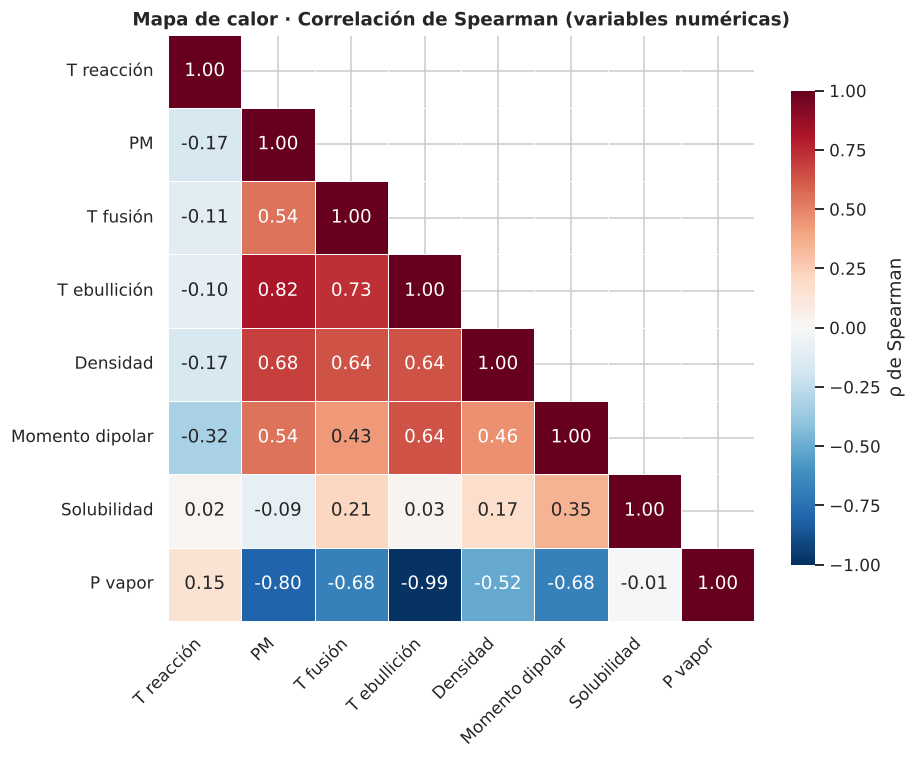

In [10]:
def mapa_calor(matriz, titulo, nombre, cmap='RdBu_r', vmin=-1, vmax=1, centro=0,
               triangular=True, etiqueta_barra='', figsize=(8.5, 7), square=True):
    plt.figure(figsize=figsize)
    mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1) if triangular else None   # oculta la mitad redundante
    sns.heatmap(matriz, mask=mascara, annot=True, fmt='.2f', cmap=cmap,
                vmin=vmin, vmax=vmax, center=centro, linewidths=.6, linecolor='white',
                square=square, cbar_kws={'label': etiqueta_barra, 'shrink': .8})
    plt.title(titulo); plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout(); guardar(nombre); plt.show()

rho = df[NUM].corr(method='spearman').rename(index=ETIQ_CORTA, columns=ETIQ_CORTA)
mapa_calor(rho, 'Mapa de calor · Correlación de Spearman (variables numéricas)',
           '02_heatmap_spearman', etiqueta_barra='ρ de Spearman')

**Interpretación.** El mapa muestra dos bloques claros:

1. **Propiedades físicas muy correlacionadas entre sí.** La pareja más fuerte es **presión de vapor – punto de ebullición (ρ = −0,99)**, seguida de **PM – punto de ebullición (ρ = +0,82)** y **PM – presión de vapor (ρ = −0,80)**. También hay relación positiva entre punto de ebullición y punto de fusión (0,73), densidad y PM (0,68), y momento dipolar y punto de ebullición (0,64).
2. **La temperatura de reacción casi no se correlaciona con las propiedades físicas** (|ρ| < 0,2), salvo una relación débil e inversa con el momento dipolar (−0,32). Esto es coherente con la química: la temperatura a la que se hace una reacción depende del mecanismo, no del tamaño de la molécula asociada. La **solubilidad** tampoco se correlaciona con ninguna propiedad (|ρ| ≤ 0,35): depende de los grupos funcionales polares (−OH, C=O), no del peso molecular.

*Precaución:* en la presión de vapor, los gases aparecen con 760 mmHg (≥ 1 atm), lo que crea muchos valores repetidos (un "techo"). Spearman lo tolera mejor que Pearson, pero conviene saberlo.

### 3.2 V de Cramér (categóricas)

**Idea.** Se cuenta cuántas filas hay en cada combinación de categorías (tabla de contingencia, `pd.crosstab`) y se compara con lo que se esperaría si las dos variables fueran independientes (prueba chi-cuadrado). La V convierte ese chi-cuadrado en una medida entre 0 (independientes) y 1 (asociación perfecta):

$$V=\sqrt{\frac{\chi^2/n}{\min(k-1,\;r-1)}}$$

donde $n$ es el número de filas, $r$ y $k$ el número de categorías de cada variable. Se usa la **corrección de sesgo de Bergsma**, porque la V normal se infla cuando hay muchas categorías y pocos datos (nuestro caso). El código de `cramers_v` es la fórmula traducida paso a paso. La función devuelve también el **valor p** de la prueba chi-cuadrado.

**Referencia para interpretar** (Cohen, aprox.): V < 0,1 asociación despreciable; 0,1–0,3 débil; 0,3–0,5 moderada; > 0,5 fuerte.

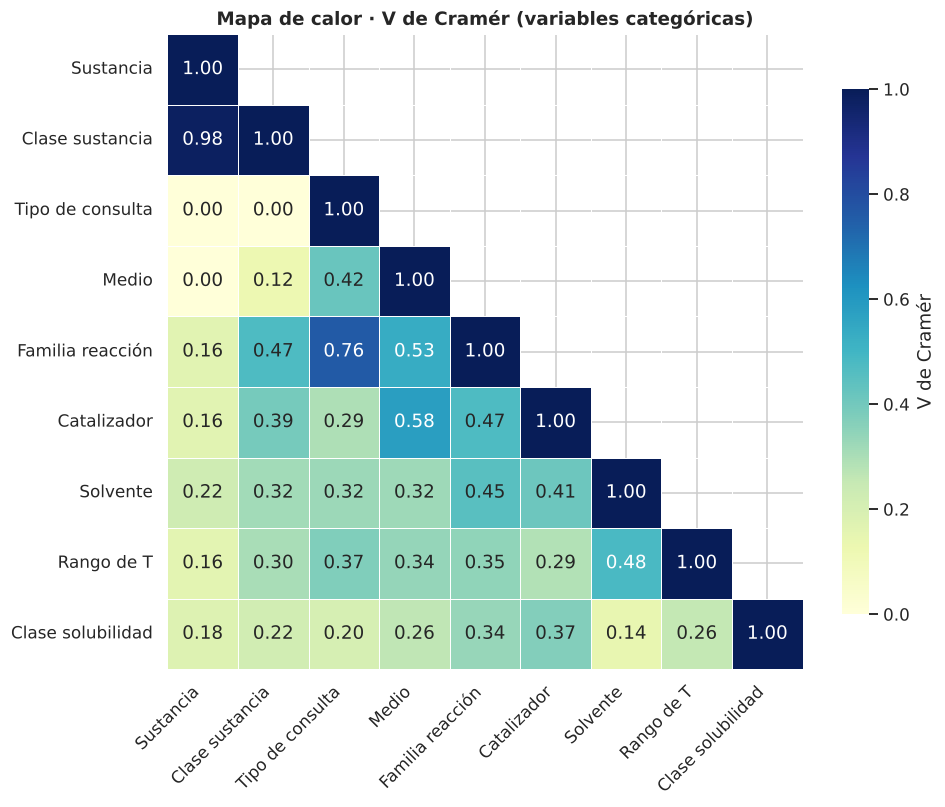

In [11]:
def cramers_v(x, y):
    # Tabla de contingencia: filas = categorías de x, columnas = categorías de y
    tabla = pd.crosstab(x, y)
    chi2, p, gl, esperada = stats.chi2_contingency(tabla, correction=False)   # chi-cuadrado de independencia
    n = tabla.values.sum()                                                    # total de observaciones
    r, k = tabla.shape                                                        # nº de filas y columnas de la tabla
    phi2 = chi2 / n
    # Corrección de sesgo (Bergsma 2013)
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    v = np.sqrt(phi2_corr / denom) if denom > 0 else 0.0
    return v, p

ETIQ_CAT = {'sustancia':'Sustancia', 'clase_cons':'Clase sustancia', 'consulta':'Tipo de consulta',
            'medio':'Medio', 'familia_rxn':'Familia reacción', 'cat_catalizador':'Catalizador',
            'cat_solvente':'Solvente', 'rango_T':'Rango de T', 'solub_clase':'Clase solubilidad'}

# Matrices de V y de valores p (cada par se calcula una sola vez)
V  = pd.DataFrame(np.eye(len(CAT_COLS)), index=CAT_COLS, columns=CAT_COLS)
Pv = pd.DataFrame(np.zeros((len(CAT_COLS),) * 2), index=CAT_COLS, columns=CAT_COLS)
for i, a in enumerate(CAT_COLS):
    for b in CAT_COLS[i + 1:]:
        d = df[[a, b]].dropna()                         # solo filas donde ambas existen
        v, p = cramers_v(d[a], d[b])
        V.loc[a, b] = V.loc[b, a] = v
        Pv.loc[a, b] = Pv.loc[b, a] = p

mapa_calor(V.rename(index=ETIQ_CAT, columns=ETIQ_CAT),
           'Mapa de calor · V de Cramér (variables categóricas)', '03_heatmap_cramer',
           cmap='YlGnBu', vmin=0, vmax=1, centro=None, etiqueta_barra='V de Cramér', figsize=(9, 7.5))

**Interpretación.** Hay que distinguir las asociaciones **reales** de las que son **redundancias por construcción**. La celda más oscura, *clase – sustancia* (V = 0,98), no es un hallazgo: cada sustancia pertenece a una sola clase, así que una variable contiene a la otra. Lo mismo pasa con *sustancia – consulta* (V = 0), porque cada sustancia tiene exactamente 10 reacciones y 10 obtenciones.

Las asociaciones reales son:

- **Familia de reacción – tipo de consulta: V = 0,76 (fuerte).** Es la más alta, pero se explica por la química del sustrato (ver 4.8).
- **Catalizador – medio: V = 0,58** y **familia – medio: V = 0,53 (fuertes).**
- **Familia – clase de la sustancia (0,47), familia – catalizador (0,47), familia – solvente (0,45) y rango de T – solvente (0,48): moderadas.**

La **familia de reacción** aparece como la variable que organiza a las demás. En cambio, la **sustancia consultada** casi no se asocia con nada (V ≤ 0,22): el 2-metilpent-2-eno y el octano se transforman con condiciones parecidas si la transformación es la misma.

*Precaución:* con 200 filas y muchas categorías, varias celdas de la tabla de contingencia quedan casi vacías; la V corregida compensa parte del problema, pero los valores bajos (< 0,2) no deben sobreinterpretarse.

### 3.3 Razón de correlación η (categórica → numérica)

η mide cuánto de la variación de una variable numérica se explica por el grupo categórico al que pertenece cada fila:

$$\eta=\sqrt{\frac{SC_{entre}}{SC_{total}}},\qquad SC_{entre}=\sum_g n_g(\bar{x}_g-\bar{x})^2,\quad SC_{total}=\sum_i (x_i-\bar{x})^2$$

- `SC_entre` mide cuánto se separan las medias de los grupos de la media general.
- `SC_total` es la variación total.
- `η² ` se interpreta como el porcentaje de la varianza que explica la categoría. En la matriz se muestra η (no η²), por lo que un valor de 0,5 equivale a explicar 25 % de la variación.

En el código, `df.groupby(cat)` separa las filas por categoría y se calcula la media de cada grupo. Atención: con grupos pequeños η tiende a ser alto por azar; por eso se complementa en la parte 6 con la prueba de Kruskal-Wallis.

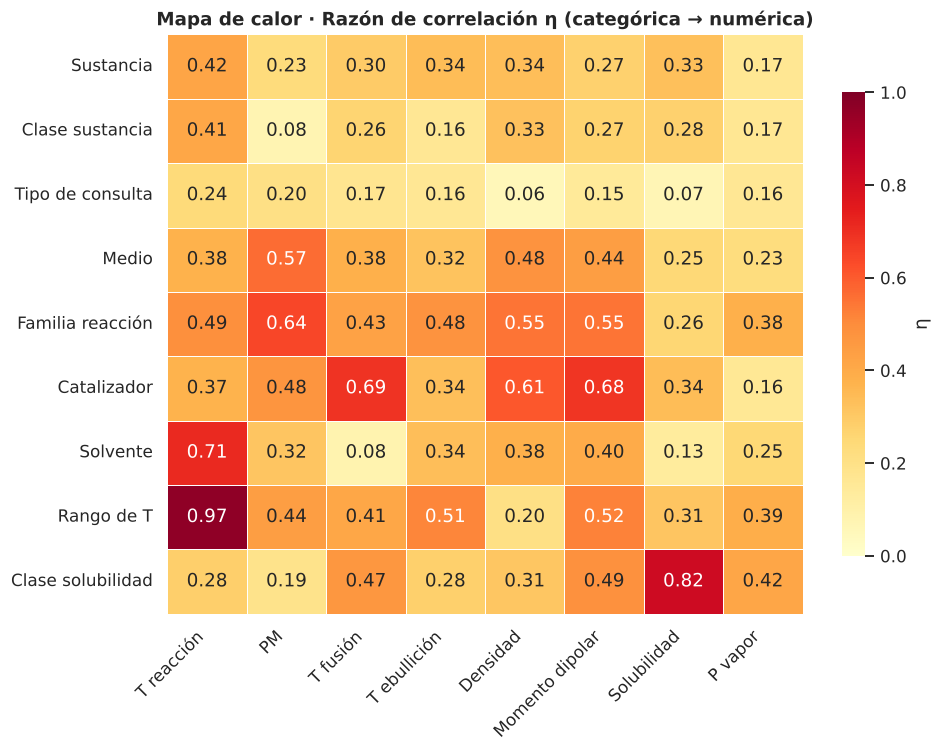

In [12]:
def eta(cat, num):
    d = pd.DataFrame({'c': cat, 'x': num}).dropna()                 # quitar filas con vacíos
    media_total = d['x'].mean()
    sc_total = ((d['x'] - media_total) ** 2).sum()                  # variación total
    sc_entre = sum(len(g) * (g['x'].mean() - media_total) ** 2      # variación entre grupos
                   for _, g in d.groupby('c', observed=True))
    return np.sqrt(sc_entre / sc_total) if sc_total > 0 else 0.0

ETA = pd.DataFrame({n: [eta(df[c], df[n]) for c in CAT_COLS] for n in NUM}, index=CAT_COLS)
mapa_calor(ETA.rename(index=ETIQ_CAT, columns=ETIQ_CORTA),
           'Mapa de calor · Razón de correlación η (categórica → numérica)', '04_heatmap_eta',
           cmap='YlOrRd', vmin=0, vmax=1, centro=None, triangular=False,
           etiqueta_barra='η', figsize=(9, 7), square=False)

**Interpretación.** De nuevo hay valores triviales: *rango de T – T de reacción* (η = 0,97) y *clase de solubilidad – solubilidad* (η = 0,82) salen altos porque la categoría se construyó **a partir** de la variable numérica. Lo que sí informa:

- **Solvente → temperatura de reacción: η = 0,71.** Las reacciones "sin solvente" (fase gas o fusión) tienen mediana de 300 °C, mientras que con solventes polares la mediana es de 25 °C. No significa que el solvente "cause" la temperatura: las reacciones térmicas en fase gas (combustión, craqueo) simplemente no usan solvente.
- **Familia de reacción → temperatura (0,49) y → PM (0,64).**
- **Catalizador → punto de fusión (0,69), momento dipolar (0,68) y densidad (0,61).** Es una asociación **indirecta**: el catalizador identifica el tipo de transformación y, con ella, el tipo de compuesto asociado (p. ej., la cal sodada, CaO, aparece en las descarboxilaciones de sales de sodio, que tienen puntos de fusión de 290–320 °C).
- **Medio → PM (0,57).**

*Precaución:* η se infla cuando hay grupos muy pequeños (p. ej., solo 6 reacciones con catalizador básico). Por eso en la parte 6 se verifica con una prueba que no depende de supuestos de normalidad.

### 3.4 Ranking de las correlaciones más fuertes

Para no elegir a ojo qué graficar, se ordenan todos los pares por intensidad. La función `top_pares(matriz, n)` convierte la mitad inferior de la matriz en una lista (`.stack()`), la ordena por valor absoluto y se queda con los `n` primeros. **Estos pares son los que se evidencian en la parte 4.**

In [13]:
def top_pares(matriz, n=8):
    inferior = matriz.where(np.tril(np.ones(matriz.shape, dtype=bool), k=-1))   # solo mitad inferior (sin la diagonal)
    serie = inferior.stack()
    return serie.reindex(serie.abs().sort_values(ascending=False).index).head(n).round(3)

print('Numéricas · Spearman (ρ):');  print(top_pares(df[NUM].corr(method='spearman')).to_string(), '\n')
print('Categóricas · V de Cramér:'); print(top_pares(V).to_string(), '\n')
print('Categórica → numérica · η (top 8):')
print(ETA.stack().sort_values(ascending=False).head(8).round(3).to_string())

Numéricas · Spearman (ρ):
Pvap      Teb   -0.989
Teb       PM     0.817
Pvap      PM    -0.804
Teb       Tf     0.734
densidad  PM     0.680
Pvap      mu    -0.677
          Tf    -0.677
densidad  Tf     0.639 

Categóricas · V de Cramér:
clase_cons       sustancia       0.982
familia_rxn      consulta        0.761
cat_catalizador  medio           0.581
familia_rxn      medio           0.535
rango_T          cat_solvente    0.484
cat_catalizador  familia_rxn     0.474
familia_rxn      clase_cons      0.474
cat_solvente     familia_rxn     0.452 

Categórica → numérica · η (top 8):
rango_T          T_rxn       0.965
solub_clase      solub_gL    0.821
cat_solvente     T_rxn       0.712
cat_catalizador  Tf          0.688
                 mu          0.684
familia_rxn      PM          0.641
cat_catalizador  densidad    0.607
medio            PM          0.566


**Interpretación y plan de la parte 4.** Con el ranking se decide qué evidenciar:

- **Numéricas:** presión de vapor – punto de ebullición, PM – punto de ebullición y PM – presión de vapor → dispersiones con tendencia (4.1), serie de sustancias consultadas (4.2) y burbujas (4.3).
- **Categóricas (ignorando las redundancias por construcción):** familia – tipo de consulta, catalizador – medio y familia – medio → probabilidades condicionales (4.4 y 4.5) y barras agrupadas (4.8).
- **Categórica → numérica:** solvente y familia → temperatura de reacción → cajas (4.6) y distribución acumulada (4.7); clase de sustancia → PM → violín (4.9).

## 4. Gráficas que evidencian las correlaciones

Criterios de elección del tipo de gráfica (guía *How to Choose the Right Data Visualization*): se escoge según **el rol** de la gráfica y **el tipo de datos**.

| Rol | Datos | Gráfica usada |
|---|---|---|
| Relación entre dos variables | numérica–numérica | Diagrama de dispersión con línea de tendencia |
| Relación entre tres variables | tres numéricas | Gráfico de burbujas |
| Comparar grupos | categórica–numérica | Diagrama de caja (con los puntos encima) y violín |
| Composición / asociación | categórica–categórica | Mapa de calor de probabilidad condicional y barras apiladas |
| Distribución | numérica | Histograma con densidad (KDE) y curva acumulada (ECDF) |

### 4.1 Dispersión con línea de tendencia (numérica–numérica)

La función `dispersion_tendencia(x, y, hue, ...)` dibuja cada reacción como un punto, añade la **recta de tendencia** (`sns.regplot` con `scatter=False` dibuja solo la recta y su banda de confianza del 95 %) y escribe en una caja el coeficiente de Spearman, su valor p y el número de datos.

- `x`, `y`: nombres de las columnas a cruzar (los puedes cambiar en vivo).
- `hue`: columna categórica que colorea los puntos (opcional).
- El **valor p** responde: *¿qué tan probable es ver una correlación así si en realidad no hubiera ninguna?* Si p < 0,05 se considera estadísticamente significativa.

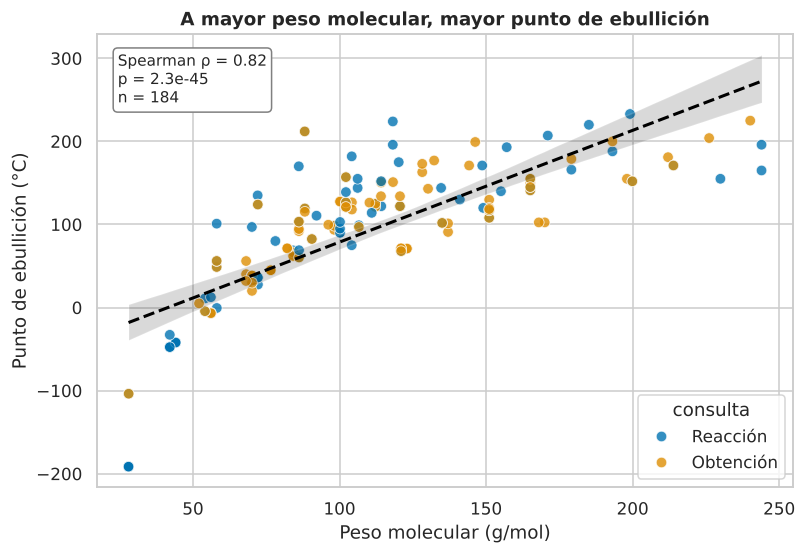

In [14]:
def dispersion_tendencia(x, y, hue=None, titulo=None, nombre=None):
    datos = df.dropna(subset=[x, y])                                  # quitar filas con vacíos en x o y
    r, p = stats.spearmanr(datos[x], datos[y])                        # correlación de Spearman y su valor p
    fig, ax = plt.subplots(figsize=(7.5, 5.2))
    sns.scatterplot(data=datos, x=x, y=y, hue=hue, s=48, alpha=.8, ax=ax)          # puntos
    sns.regplot(data=datos, x=x, y=y, scatter=False, color='black',                  # recta de tendencia
                line_kws={'lw': 2, 'ls': '--'}, ax=ax)
    ax.set(xlabel=ETIQ.get(x, x), ylabel=ETIQ.get(y, y), title=titulo or f'{ETIQ.get(y, y)} vs {ETIQ.get(x, x)}')
    ax.text(.03, .96, f'Spearman ρ = {r:.2f}\np = {p:.1e}\nn = {len(datos)}', transform=ax.transAxes,
            va='top', fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='gray'))
    plt.tight_layout()
    if nombre: guardar(nombre)
    plt.show()
    return r, p

r1 = dispersion_tendencia('PM', 'Teb', hue='consulta',
                          titulo='A mayor peso molecular, mayor punto de ebullición', nombre='05_PM_vs_Teb')

**Interpretación.** La tendencia es clara y creciente: ρ = 0,82 con p ≈ 10⁻⁴⁵ (n = 184), de modo que el PM explica cerca de **dos tercios (ρ² = 0,67)** de la variación del punto de ebullición. **Se confirma H1:** a más masa, más electrones y más fuerzas de dispersión de London, y por tanto más energía para pasar a gas. La relación es **curva** (sube con fuerte pendiente en PM bajos y se aplana después), por eso conviene Spearman y no una recta de Pearson. La dispersión alrededor de la tendencia viene de la **polaridad**: a igual PM, los compuestos con grupos −OH o C=O (alcoholes, aldehídos, cetonas) tienen puntos de ebullición más altos que los hidrocarburos por puentes de hidrógeno y fuerzas dipolo-dipolo. Los puntos de *Reacción* y de *Obtención* se mezclan en la misma nube: la dirección de la consulta no cambia la relación.

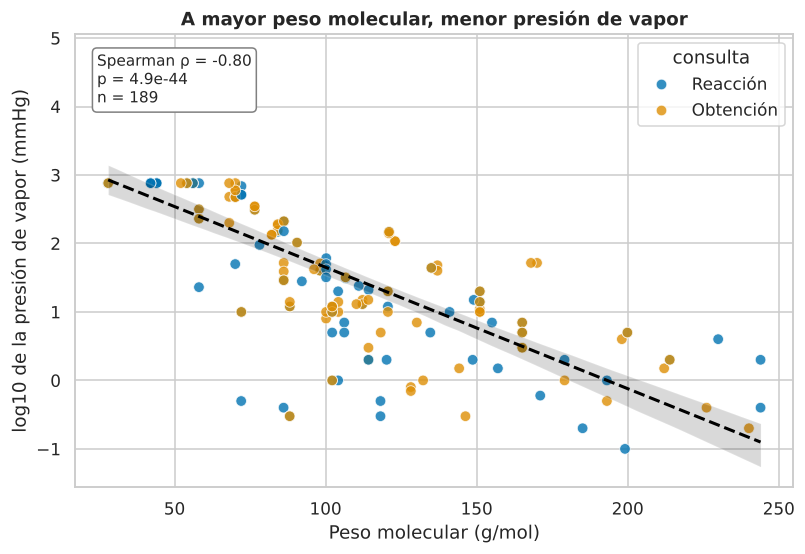

In [15]:
r2 = dispersion_tendencia('PM', 'Pvap_log', hue='consulta',
                          titulo='A mayor peso molecular, menor presión de vapor', nombre='06_PM_vs_Pvap')

**Interpretación.** Tendencia **decreciente** con ρ = −0,80 (n = 189): las moléculas más pesadas son menos volátiles. Se usa log₁₀ de la presión de vapor porque abarca varios órdenes de magnitud (0,1 a 56 500 mmHg). La banda horizontal en la parte superior (log₁₀ 760 ≈ 2,88) corresponde a gases con presión de vapor reportada como 760 mmHg, un **efecto de techo** de la tabla, no una propiedad real; esto explica parte de la dispersión. La relación con el PM es más débil que con el punto de ebullición porque la presión de vapor depende directamente de la temperatura de ebullición, y el PM solo explica esta última de forma indirecta.

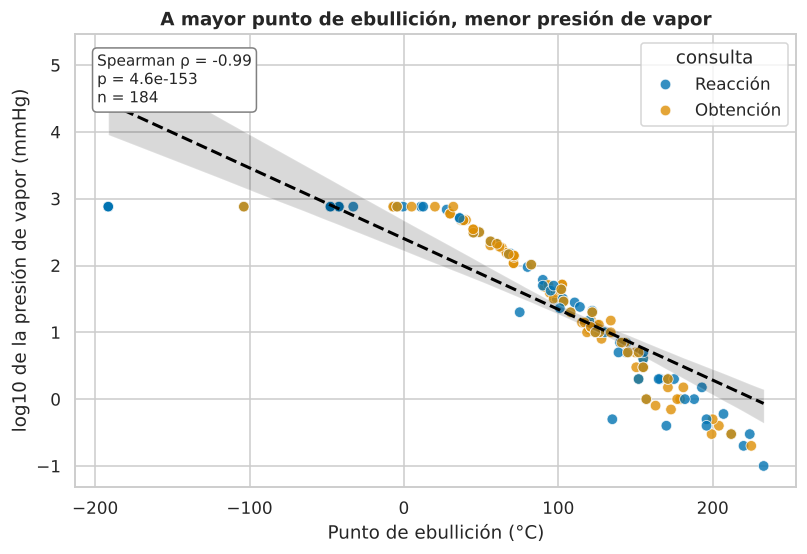

In [16]:
r3 = dispersion_tendencia('Teb', 'Pvap_log', hue='consulta',
                          titulo='A mayor punto de ebullición, menor presión de vapor', nombre='07_Teb_vs_Pvap')

**Interpretación.** La relación es casi perfecta: **ρ = −0,99**. Es esperable por la ecuación de Clausius-Clapeyron ($\ln P = -\Delta H_{vap}/(RT)+C$): un líquido que hierve a mayor temperatura tiene menor presión de vapor a temperatura ambiente. Consecuencia práctica: **punto de ebullición y presión de vapor aportan casi la misma información** (colinealidad). Si se construye un modelo (o un filtro en Power BI) basta con una de las dos; usar ambas no agrega información independiente.

### 4.2 Tendencia en la serie de sustancias consultadas

Las 10 sustancias consultadas incluyen una **serie homóloga** (pentano → hexano → heptano → octano). En una serie homóloga cada miembro agrega un grupo $-CH_2-$, y el punto de ebullición debe subir de forma casi regular. El código toma la hoja `Sustancias`, filtra con `sust['Rol'] == 'Consultada'` (el `==` crea una máscara de verdadero/falso y los corchetes se quedan con las filas verdaderas) y dibuja PM contra T de ebullición con `plt.annotate` para escribir el nombre de cada punto. Se colorea por la clase de la sustancia.

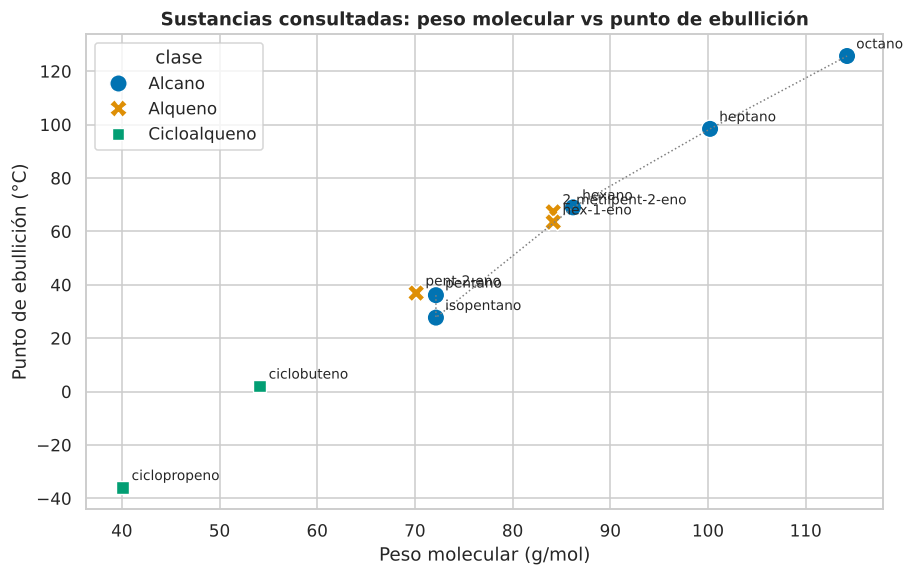

In [17]:
cons = sust[sust['Rol'] == 'Consultada'].copy()                                   # solo las 10 sustancias consultadas
cons['Teb'] = pd.to_numeric(cons['Punto de ebullición (°C)'], errors='coerce')
cons['PM']  = cons['Peso molecular (g/mol)']
cons['clase'] = cons['Sustancia'].map(CLASE_CONS)

fig, ax = plt.subplots(figsize=(8.5, 5.4))
sns.scatterplot(data=cons, x='PM', y='Teb', hue='clase', style='clase', s=130, ax=ax)
for _, f in cons.iterrows():                                                      # escribir el nombre de cada punto
    ax.annotate(f['Sustancia'], (f['PM'], f['Teb']), xytext=(6, 5), textcoords='offset points', fontsize=9)
alc = cons[cons['clase'] == 'Alcano'].sort_values('PM')                           # unir los alcanos lineales con una línea
ax.plot(alc['PM'], alc['Teb'], color='gray', lw=1, ls=':')
ax.set(xlabel=ETIQ['PM'], ylabel=ETIQ['Teb'], title='Sustancias consultadas: peso molecular vs punto de ebullición')
plt.tight_layout(); guardar('08_serie_sustancias_consultadas'); plt.show()

**Interpretación.** En la serie de alcanos lineales el punto de ebullición sube de forma regular con cada $-CH_2-$: pentano 36,1 → hexano 69,0 → heptano 98,4 → octano 125,7 °C, es decir, **≈ +33, +29 y +27 °C por carbono** (el incremento disminuye ligeramente). Otros detalles que se leen en la gráfica:

- El **isopentano** (ramificado) hierve más bajo (27,7 °C) que el **pentano** (36,1 °C) con el mismo PM: la ramificación reduce el área de contacto entre moléculas y con ello las fuerzas de London.
- Los **alquenos** hierven casi igual que el alcano de igual número de carbonos (pent-2-eno 36,9 vs pentano 36,1; hex-1-eno 63,5 vs hexano 69,0): el doble enlace casi no cambia la polaridad.
- Los **cicloalquenos** (ciclopropeno −36 °C, ciclobuteno 2 °C) tienen PM bajo y son gases o casi gases a temperatura ambiente.

### 4.3 Burbujas: tres variables numéricas a la vez

El gráfico de burbujas es una dispersión donde el **tamaño** del punto codifica una tercera variable numérica. Con `sns.scatterplot(size='densidad', sizes=(20, 250))` el tamaño va de 20 a 250 puntos. La guía recomienda no pasar de tres variables en un mismo gráfico para mantenerlo legible.

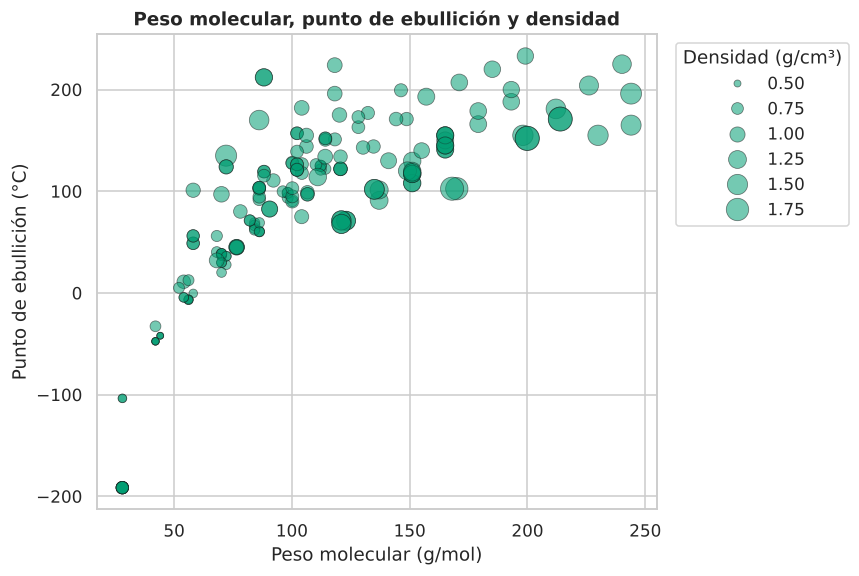

In [18]:
datos = df.dropna(subset=['PM', 'Teb', 'densidad'])
fig, ax = plt.subplots(figsize=(8, 5.4))
sns.scatterplot(data=datos, x='PM', y='Teb', size='densidad', sizes=(20, 250),
                alpha=.55, color=sns.color_palette()[2], edgecolor='k', ax=ax)
ax.set(xlabel=ETIQ['PM'], ylabel=ETIQ['Teb'], title='Peso molecular, punto de ebullición y densidad')
ax.legend(title='Densidad (g/cm³)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); guardar('09_burbujas_PM_Teb_densidad'); plt.show()

**Interpretación.** Las burbujas crecen hacia la derecha y hacia arriba, es decir, **los compuestos pesados y de alto punto de ebullición también son los más densos** (ρ densidad–PM = 0,68). Las burbujas más grandes (> 1,8 g/cm³) son derivados **halogenados** (1,2-dibromociclopropano 1,98; 1,2-dibromociclobutano 1,95; 3-yodopropeno 1,85): el bromo y el yodo aumentan el PM y la densidad más que cualquier cadena hidrocarbonada. Con esta gráfica se ven a la vez tres propiedades que obedecen al mismo origen: la masa y el tamaño molecular.

### 4.4 Probabilidad condicional: familia de reacción y medio (categórica–categórica)

Un mapa de calor de **probabilidad condicional** responde preguntas del tipo: *si la reacción es de eliminación, ¿cuál es la probabilidad de que ocurra en medio básico?*, es decir $P(\text{medio}\mid\text{familia})$.

- `pd.crosstab(familia, medio, normalize='index')` cuenta combinaciones y **divide cada fila entre su total**, así cada fila suma 1 (100 %).
- `* 100` pasa a porcentaje y `fmt='.0f'` lo escribe sin decimales.
- Se acompaña de un diagrama de **barras apiladas** (`.plot(kind='barh', stacked=True)`) que muestra el mismo reparto como composición.

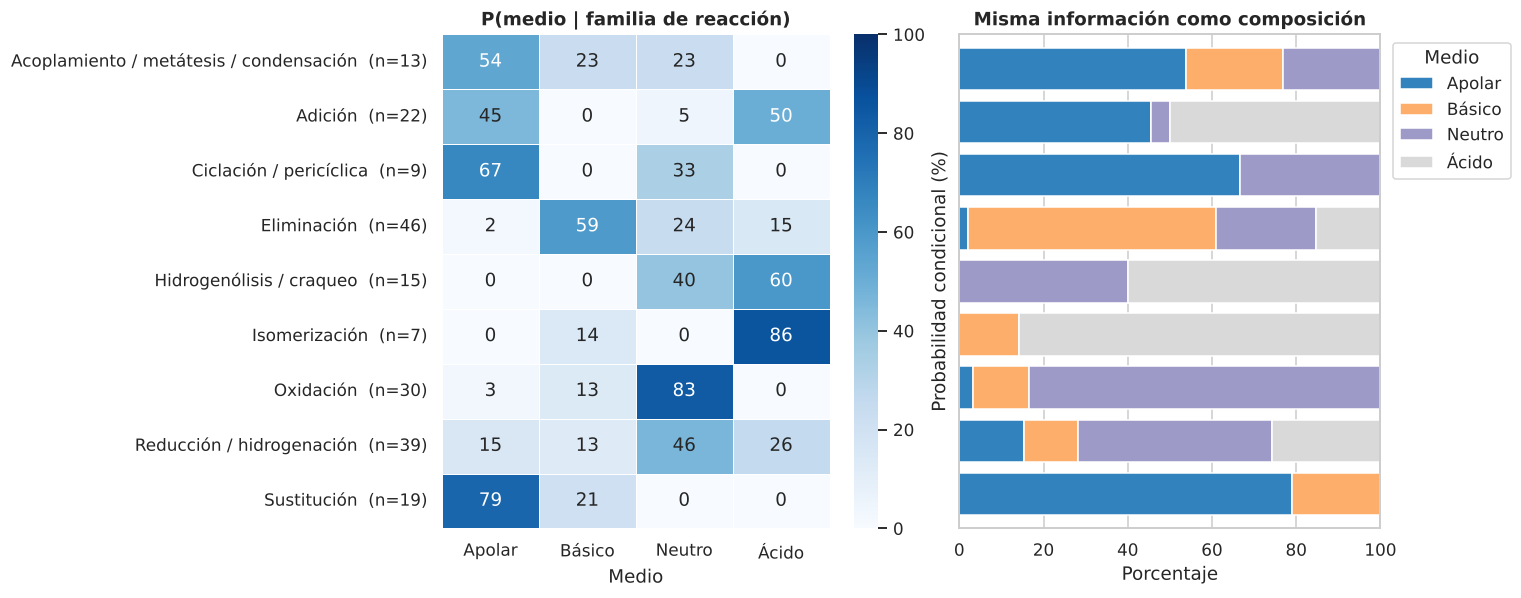

In [19]:
def prob_condicional(fila, columna, titulo, nombre, cmap='Blues'):
    # P(columna | fila): cada fila de la tabla suma 100 %
    tabla = pd.crosstab(df[fila], df[columna], normalize='index') * 100
    n_fila = df[fila].value_counts()
    tabla.index = [f'{i}  (n={n_fila[i]})' for i in tabla.index]                   # añadir el tamaño de cada grupo
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'width_ratios': [1.15, 1]})
    sns.heatmap(tabla, annot=True, fmt='.0f', cmap=cmap, vmin=0, vmax=100, linewidths=.5,
                cbar_kws={'label': 'Probabilidad condicional (%)'}, ax=axes[0])
    axes[0].set(title=titulo, xlabel=ETIQ_CAT.get(columna, columna), ylabel='')
    tabla.iloc[::-1].plot(kind='barh', stacked=True, ax=axes[1], colormap='tab20c', width=.8)   # [::-1] invierte el orden para que coincida con el mapa de calor
    axes[1].set(title='Misma información como composición', xlabel='Porcentaje', ylabel='')
    axes[1].legend(title=ETIQ_CAT.get(columna, columna), bbox_to_anchor=(1.01, 1), loc='upper left')
    axes[1].set_yticklabels([])
    plt.tight_layout(); guardar(nombre); plt.show()
    return tabla

t_fam_medio = prob_condicional('familia_rxn', 'medio', 'P(medio | familia de reacción)', '10_prob_familia_medio')

**Interpretación.** Los porcentajes de cada fila son la probabilidad condicional $P(\text{medio}\mid\text{familia})$ y se comparan contra la probabilidad global del medio (neutro 33,5 %, apolar 23 %, básico 22 %, ácido 21,5 %). Los patrones coinciden con los mecanismos:

- **Eliminación → básico (59 %)**, 2,7 veces más probable que el 22 % global, coherente con E2 por bases fuertes (t-BuOK, KOH/etanol).
- **Sustitución → apolar (79 %)**: la halogenación radicalaria ocurre en medio apolar con luz UV.
- **Oxidación → neutro (83 %)**: combustiones, epoxidaciones y dihidroxilaciones no requieren un medio ácido o básico.
- **Isomerización → ácido (86 %)**: se catalizan con ácidos de Lewis o de Brønsted (AlCl₃/HCl, zeolitas).
- **Hidrogenólisis/craqueo → ácido (60 %)** y **adición → ácido (50 %) o apolar (45 %)**, sobre todo adiciones electrofílicas con HX, H₂O/H⁺ o halógenos.

**Se confirma H2** (V = 0,53). *Precaución:* en isomerización (n = 7) y ciclación (n = 9) los porcentajes cambian mucho con una sola reacción; se leen como tendencia, no como probabilidad estable.

### 4.5 Familia de reacción y catalizador

Mismo procedimiento con la categoría de catalizador: ¿qué tipo de catalizador es **más probable** para cada familia de reacción?

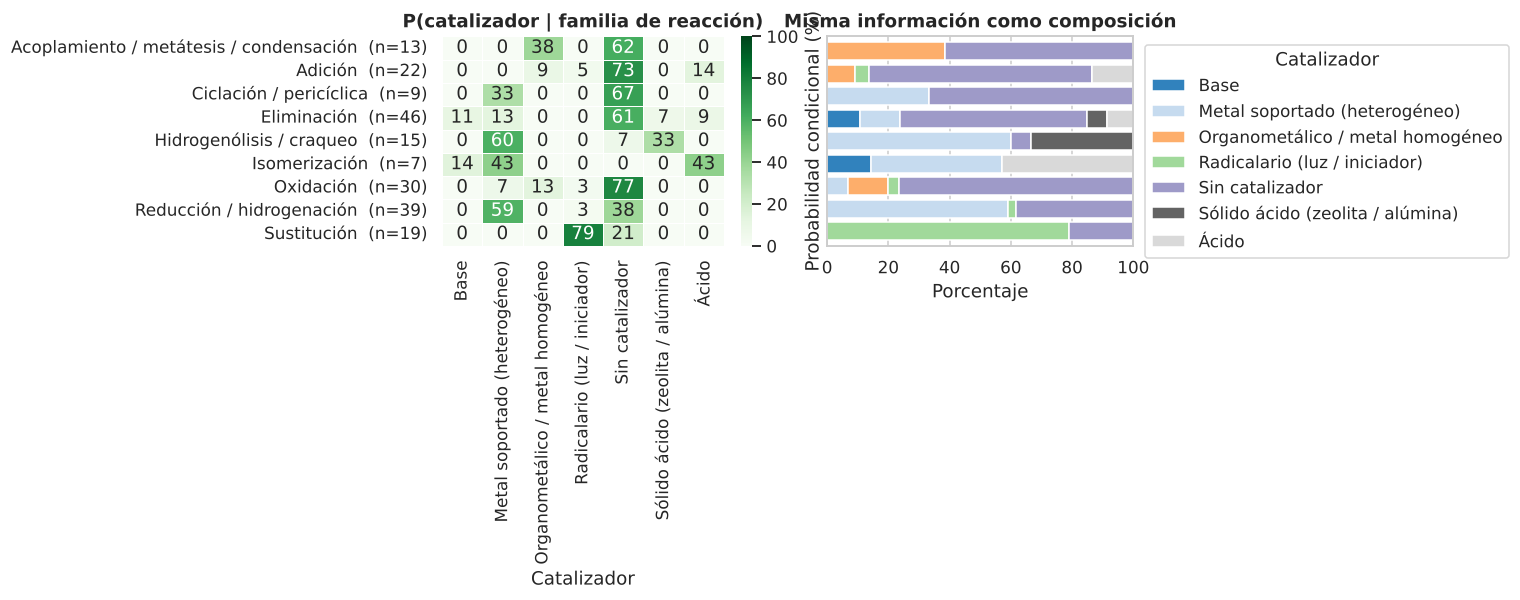

In [20]:
t_fam_cat = prob_condicional('familia_rxn', 'cat_catalizador', 'P(catalizador | familia de reacción)',
                             '11_prob_familia_catalizador', cmap='Greens')

**Interpretación.** El catalizador también depende de la familia. **Sustitución → radicalario (79 %)** (luz UV, AIBN); **reducción/hidrogenación → metal soportado (59 %)** (Pd/C, PtO₂, Ni Raney); **hidrogenólisis/craqueo → metal soportado (60 %) o sólido ácido (33 %)** (zeolitas, alúmina); **acoplamiento/metátesis → organometálico (38 %)** (Grubbs II, CuI). En cambio, **oxidación (77 %), eliminación (61 %) y adición (73 %)** se hacen con frecuencia **sin catalizador** (combustión por ignición, eliminaciones con una base como reactivo, adiciones de halógenos). Es el mismo resultado que V = 0,47 (familia – catalizador). *Precaución:* 83 % de las celdas de la tabla tienen frecuencia esperada menor que 5, así que el valor p de chi-cuadrado es solo aproximado (ver parte 6).

### 4.6 Temperatura de reacción según la familia (categórica–numérica)

El **diagrama de caja** resume una distribución con cinco números: la caja va del cuartil 1 al 3 (50 % central de los datos), la línea interior es la mediana y los bigotes llegan hasta 1,5 veces el rango de la caja; los puntos fuera son **valores atípicos**. Se superponen los puntos reales con `sns.stripplot` (con `jitter` se desplazan un poco para no taparse) porque con grupos pequeños el resumen puede engañar. Se orienta **horizontal** (`y=familia`) porque los nombres son largos. Se ordenan las familias por su mediana con `.groupby(...).median().sort_values()`.

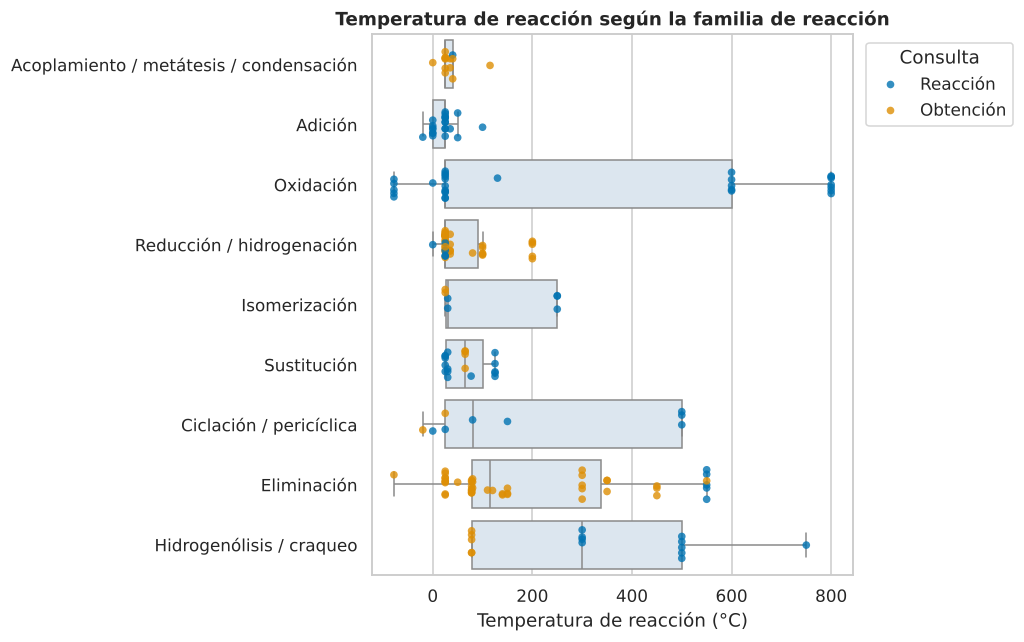

In [21]:
orden = df.groupby('familia_rxn')['T_rxn'].median().sort_values().index           # familias ordenadas por mediana de T
fig, ax = plt.subplots(figsize=(9.5, 6))
sns.boxplot(data=df, y='familia_rxn', x='T_rxn', order=orden, color='#d9e6f2', fliersize=0, ax=ax)   # cajas
sns.stripplot(data=df, y='familia_rxn', x='T_rxn', order=orden, hue='consulta', jitter=.25,
              size=5, alpha=.8, ax=ax)                                                                 # puntos reales
ax.set(xlabel=ETIQ['T_rxn'], ylabel='', title='Temperatura de reacción según la familia de reacción')
ax.legend(title='Consulta', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); guardar('12_box_T_por_familia'); plt.show()

**Interpretación.** La temperatura se agrupa en **dos regímenes**:

- **Temperatura moderada (mediana ≈ 25–30 °C):** adición, reducción/hidrogenación, isomerización, acoplamiento/metátesis y sustitución (65 °C).
- **Temperatura alta:** **hidrogenólisis/craqueo** tiene la mediana más alta (300 °C, rango 78–750 °C) y la **eliminación** le sigue (mediana 115 °C, hasta 550 °C por las deshidrogenaciones y las pirólisis).

**Oxidación** es un caso especial: su mediana es 25 °C pero la caja llega hasta 600 °C y los puntos se ven en dos grupos, porque mezcla oxidaciones suaves (epoxidación, ozonólisis a −78 °C, dihidroxilación a 0–25 °C) con **combustiones a 600–800 °C**. Aquí la mediana no resume bien la familia: la distribución es **bimodal**. La prueba de Kruskal-Wallis (parte 6) confirma que las diferencias entre familias son significativas con un efecto grande (ε² = 0,22). Los puntos de color muestran además que casi toda la eliminación y la reducción son *Obtenciones* y que toda la adición y la oxidación son *Reacciones*.

### 4.7 Distribución de la temperatura de reacción: histograma, densidad y probabilidad acumulada

- **Histograma + KDE** (`sns.histplot(..., kde=True)`): las barras cuentan reacciones por intervalo de temperatura (`bins` = número de intervalos) y la curva suave es la estimación de la densidad.
- **ECDF** (`sns.ecdfplot`): función de distribución **acumulada empírica**. Su altura en una temperatura $t$ es $P(T\le t)$, o sea, la probabilidad de que una reacción de la tabla ocurra a $t$ °C o menos. Es la gráfica directa de la *probabilidad*. Se compara *Reacción* contra *Obtención* con `hue='consulta'`.

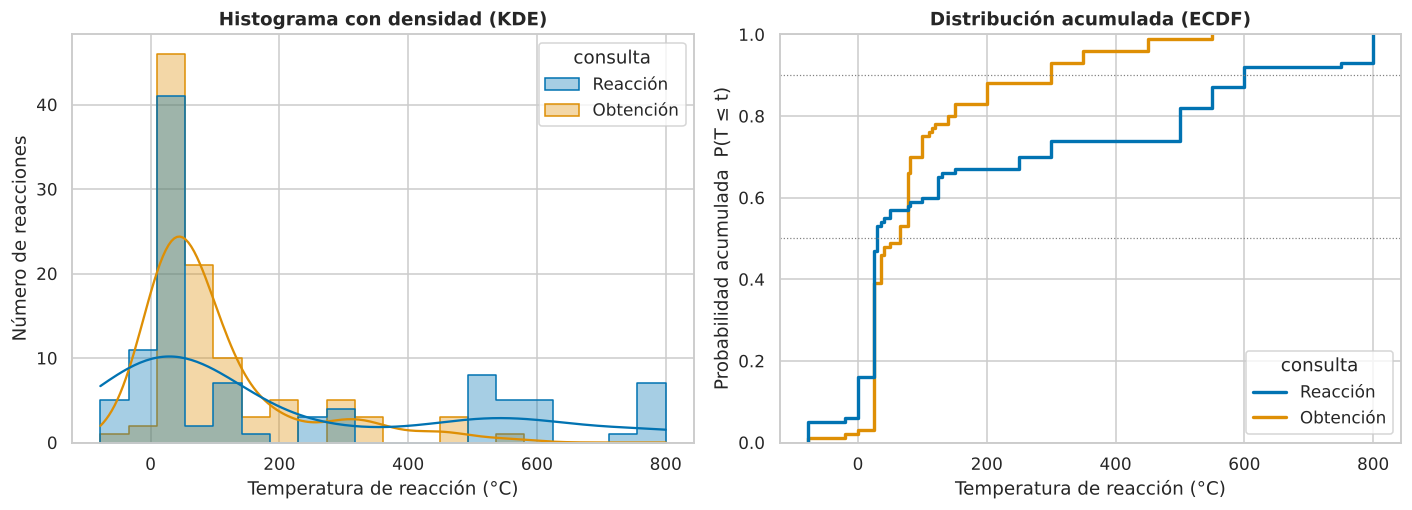

,count,mean,std,min,50%,90%,max
consulta,,,,,,,
Obtención,100.0,98.0,115.9,-78.0,65.0,300.0,550.0
Reacción,100.0,199.3,268.4,-78.0,30.0,600.0,800.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(data=df, x='T_rxn', hue='consulta', bins=20, kde=True, element='step', alpha=.35, ax=axes[0])
axes[0].set(xlabel=ETIQ['T_rxn'], ylabel='Número de reacciones', title='Histograma con densidad (KDE)')

sns.ecdfplot(data=df, x='T_rxn', hue='consulta', lw=2.2, ax=axes[1])
axes[1].set(xlabel=ETIQ['T_rxn'], ylabel='Probabilidad acumulada  P(T ≤ t)', title='Distribución acumulada (ECDF)')
for y in (.5, .9):                                                                      # guías en la mediana y el percentil 90
    axes[1].axhline(y, color='gray', lw=.8, ls=':')
plt.tight_layout(); guardar('13_hist_ecdf_temperatura'); plt.show()

# Cuantiles por tipo de consulta (para citar en el informe)
df.groupby('consulta')['T_rxn'].describe(percentiles=[.5, .9]).round(1)

**Interpretación.** El histograma muestra una **distribución muy asimétrica con un pico en temperatura ambiente**: el 51,5 % de las 200 reacciones ocurre a 40 °C o menos. La curva acumulada permite leer probabilidades directamente: por ejemplo, la mediana de las *Reacciones* es 30 °C y la de las *Obtenciones* es 65 °C, pero la cola de las *Reacciones* llega mucho más lejos: su **percentil 90 es 600 °C frente a 300 °C** en las obtenciones, y su máximo es 800 °C frente a 550 °C. De los 30 registros con 400 °C o más, **26 son Reacciones** (combustión, craqueo, reformado). Es decir, las curvas se cruzan: las *Reacciones* empiezan más "frías" pero terminan mucho más "calientes".

### 4.8 Reacciones vs obtenciones por familia (barras agrupadas)

El **gráfico de barras agrupadas** compara una categoría (familia) entre dos grupos (Reacción / Obtención). `sns.countplot(hue='consulta')` pone una barra por grupo. Si la distribución de familias fuera igual en ambos grupos, las barras de cada par tendrían alturas similares.

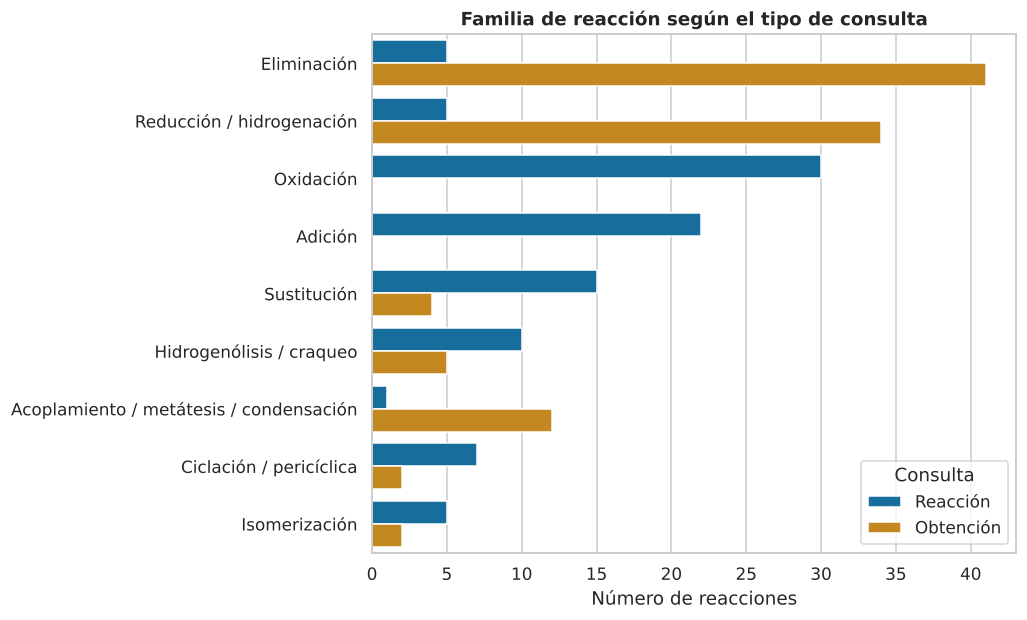

In [23]:
orden = df['familia_rxn'].value_counts().index
fig, ax = plt.subplots(figsize=(9.5, 5.8))
sns.countplot(data=df, y='familia_rxn', hue='consulta', order=orden, ax=ax)
ax.set(xlabel='Número de reacciones', ylabel='', title='Familia de reacción según el tipo de consulta')
ax.legend(title='Consulta')
plt.tight_layout(); guardar('14_barras_familia_consulta'); plt.show()

**Interpretación.** Esta gráfica explica el valor V = 0,76 de *familia – consulta*. **La adición (22) y la oxidación (30) aparecen solo como *Reacción*** (0 obtenciones), porque son lo que les pasa a los alquenos y alcanos. En cambio, **la eliminación (41 de 46), la reducción/hidrogenación (34 de 39) y el acoplamiento (12 de 13) son sobre todo *Obtención***: los alquenos se obtienen por eliminación y los alcanos por reducción o hidrogenación. La sustitución es mayoritariamente *Reacción* (15 de 19). Entonces, **la asociación no es un hallazgo estadístico independiente sino la consecuencia de la química del grupo funcional** y del diseño del proyecto. En la sustentación conviene decirlo así: "consulta" no causa la familia, ambas reflejan si el alcano/alqueno es reactante o producto.

### 4.9 Violín: propiedades según la clase de sustancia consultada

El **violín** combina un diagrama de caja con una curva de densidad espejada: donde el violín es ancho hay más datos. Con `split=True` se divide cada violín en dos mitades (una por tipo de consulta) para compararlas sin duplicar figuras; `inner='quart'` dibuja los cuartiles.

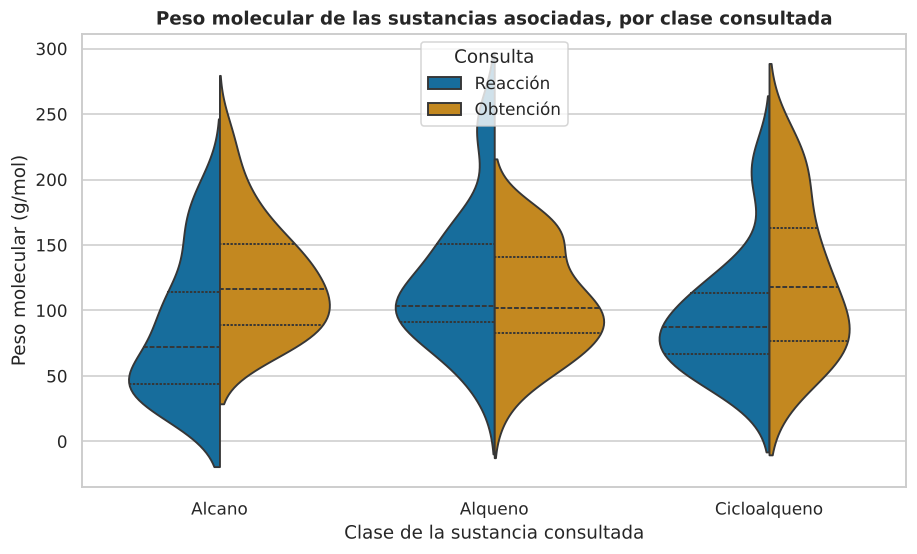

In [24]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.violinplot(data=df, x='clase_cons', y='PM', hue='consulta', split=True, inner='quart',
               order=['Alcano', 'Alqueno', 'Cicloalqueno'], ax=ax)
ax.set(xlabel='Clase de la sustancia consultada', ylabel=ETIQ['PM'],
       title='Peso molecular de las sustancias asociadas, por clase consultada')
ax.legend(title='Consulta')
plt.tight_layout(); guardar('15_violin_PM_clase'); plt.show()

**Interpretación.** Este es un resultado **nulo** y también informa. El peso molecular de las sustancias asociadas es parecido sin importar la clase consultada: medias de 105,7 (alcano), 114,5 (alqueno) y 109,9 g/mol (cicloalqueno); medianas de 102,2, 102,2 y 90,6 g/mol; y la razón de correlación es η = 0,08 (casi sin efecto). Las mitades *Reacción* y *Obtención* de cada violín también se parecen. Conclusión: **la clase de la sustancia de partida no determina el tamaño de las moléculas con las que se relaciona**; eso lo determina el tipo de transformación (por ejemplo, una combustión da CO₂ de 44 g/mol, mientras que una cloración da un haluro de 106 g/mol).

### 4.10 Matriz de dispersión (pairplot): vista conjunta de las propiedades físicas

`sns.pairplot` genera una cuadrícula con la dispersión de **todos los pares** de variables y la densidad de cada una en la diagonal (`corner=True` quita la mitad repetida). Sirve para confirmar de un vistazo lo visto en el mapa de calor y detectar relaciones **no lineales** que un coeficiente no captura.

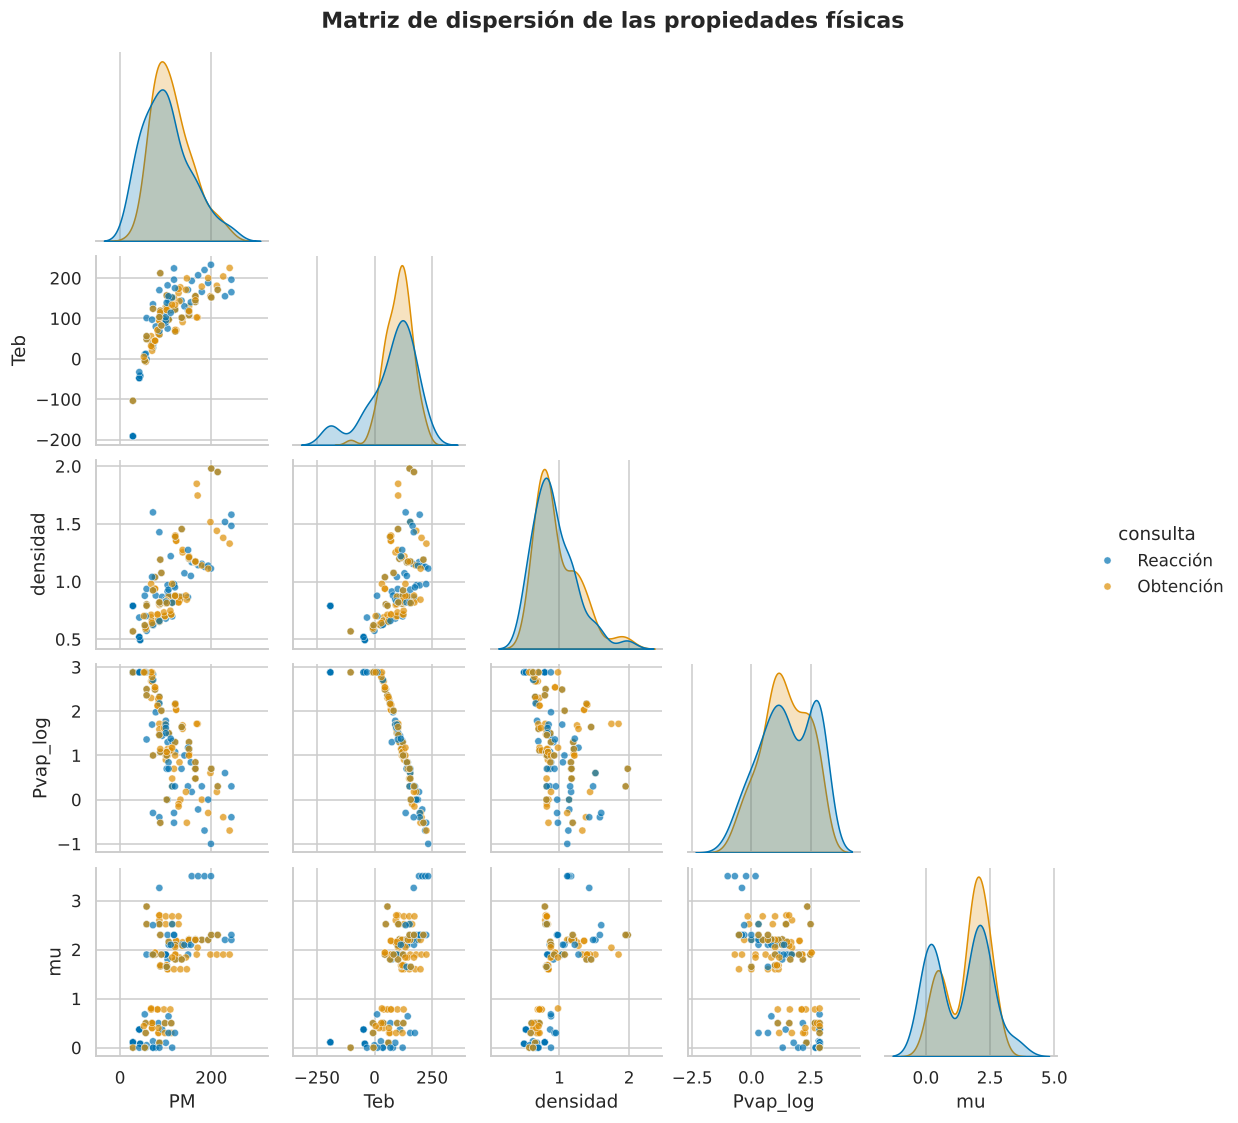

In [25]:
vars_pair = ['PM', 'Teb', 'densidad', 'Pvap_log', 'mu']
g = sns.pairplot(df.dropna(subset=vars_pair), vars=vars_pair, hue='consulta', corner=True,
                 diag_kind='kde', plot_kws={'s': 22, 'alpha': .7}, height=2.0)
g.figure.suptitle('Matriz de dispersión de las propiedades físicas', y=1.02, fontweight='bold')
guardar('16_pairplot_propiedades'); plt.show()

**Interpretación.** La matriz confirma lo visto en el mapa de calor y añade tres detalles que un coeficiente no muestra: (1) **PM–punto de ebullición es una relación curva** (sube rápido y luego se aplana); (2) **punto de ebullición – log presión de vapor es casi una línea recta decreciente**, con la banda plana del "techo" de 760 mmHg en los gases; (3) el **momento dipolar es bimodal**: un grupo con μ entre 0 y 0,8 D (hidrocarburos y compuestos poco polares) y otro entre 1,6 y 2,7 D (con grupos polares, algunos con 3,5 D). Por eso su correlación con las demás variables es moderada: en realidad separa dos tipos de sustancias más que graduar una escala continua. Las nubes de *Reacción* y *Obtención* se superponen en casi todos los paneles.

## 5. Comportamientos anómalos (valores atípicos)

Un valor atípico es un dato muy alejado del resto. No siempre es un error: puede ser una **reacción realmente distinta** (por ejemplo, una combustión a 800 °C entre reacciones a 25 °C) o un **dato mal digitado** que hay que revisar en SciFinder.

**Regla del rango intercuartílico (IQR):** se calcula $IQR = Q_3-Q_1$ y se marca como atípico todo valor menor que $Q_1-1{,}5\,IQR$ o mayor que $Q_3+1{,}5\,IQR$ (es la misma regla que usa el diagrama de caja). `df[col].quantile([.25, .75])` entrega los cuartiles.

Para comparar variables con escalas tan distintas en una sola gráfica se **estandarizan** (puntaje z = (valor − media) / desviación) y se dibuja un diagrama de caja por variable.

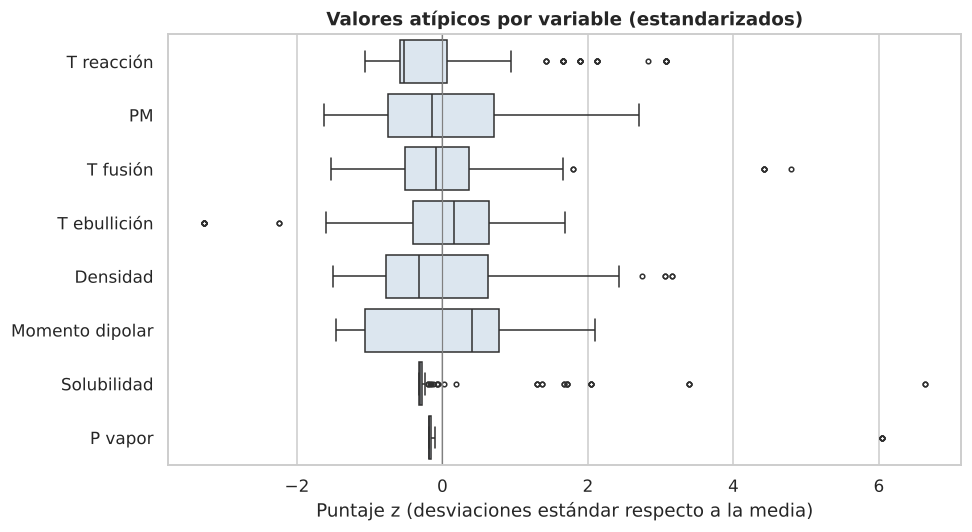

,variable,n_atípicos,límite inf.,límite sup.
0,Temperatura de reacción (°C),30,-181.25,368.75
1,Peso molecular (g/mol),0,-36.85,253.68
2,Punto de fusión (°C),7,-230.64,62.26
3,Punto de ebullición (°C),9,-80.87,279.32
4,Densidad (g/cm³),5,0.06,1.84
5,Momento dipolar (D),0,-2.32,4.91
6,Solubilidad en agua (g/L),29,-1.35,2.41
7,Presión de vapor (mmHg),5,-461.50,782.50


In [26]:
def atipicos_iqr(col):
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    return fuera, (round(lim_inf, 2), round(lim_sup, 2))

# Gráfica: puntajes z de las variables numéricas
z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
z.columns = [ETIQ_CORTA[c] for c in z.columns]
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=z, orient='h', color='#d9e6f2', fliersize=3, ax=ax)
ax.axvline(0, color='gray', lw=.8)
ax.set(xlabel='Puntaje z (desviaciones estándar respecto a la media)', title='Valores atípicos por variable (estandarizados)')
plt.tight_layout(); guardar('17_atipicos_z'); plt.show()

# Tabla: cuántos atípicos tiene cada variable
resumen = []
for c in NUM:
    f, lim = atipicos_iqr(c)
    resumen.append({'variable': ETIQ[c], 'n_atípicos': len(f), 'límite inf.': lim[0], 'límite sup.': lim[1]})
pd.DataFrame(resumen)

In [27]:
# Detalle de las reacciones atípicas en temperatura de reacción y en punto de fusión
for c in ['T_rxn', 'Tf']:
    f, lim = atipicos_iqr(c)
    print(f'\n{ETIQ[c]} · límites IQR = {lim} · {len(f)} atípicos')
    display(f[['ID', 'sustancia', 'consulta', 'nombre_rxn', 'asociada', c]].sort_values(c).head(12))


Temperatura de reacción (°C) · límites IQR = (-181.25, 368.75) · 30 atípicos


,ID,sustancia,consulta,nombre_rxn,asociada,T_rxn
198,R199,ciclobuteno,Obtención,Pirólisis de ésteres,acetato de ciclobutilo,450
119,R120,pent-2-eno,Obtención,Pirólisis de ésteres,acetato de pentan-2-ilo,450
159,R160,hex-1-eno,Obtención,Pirólisis de ésteres,acetato de hexilo,450
6,R007,pentano,Reacción,Craqueo catalítico,propeno,500
65,R066,heptano,Reacción,Reformado catalítico (aromatización),tolueno,500
25,R026,isopentano,Reacción,Craqueo catalítico,2-metilpropeno,500
45,R046,hexano,Reacción,Reformado catalítico (aromatización),benceno,500
47,R048,hexano,Reacción,Craqueo catalítico,propeno,500
67,R068,heptano,Reacción,Craqueo catalítico,propeno,500
85,R086,octano,Reacción,Reformado catalítico (aromatización),"1,2-dimetilbenceno",500



Punto de fusión (°C) · límites IQR = (-230.64, 62.26) · 7 atípicos


,ID,sustancia,consulta,nombre_rxn,asociada,Tf
197,R198,ciclobuteno,Obtención,Eliminación de sulfonato,tosilato de ciclobutilo,72.0
166,R167,ciclopropeno,Reacción,Ozonólisis reductiva,propanodial,72.0
37,R038,isopentano,Obtención,Descarboxilación con cal sodada,4-metilpentanoato de sodio,290.0
57,R058,hexano,Obtención,Descarboxilación con cal sodada,heptanoato de sodio,290.0
97,R098,octano,Obtención,Descarboxilación con cal sodada,nonanoato de sodio,290.0
77,R078,heptano,Obtención,Descarboxilación con cal sodada,octanoato de sodio,290.0
17,R018,pentano,Obtención,Descarboxilación con cal sodada,hexanoato de sodio,320.0


**Interpretación.** Los atípicos de esta tabla **no son errores**: son reacciones o sustancias genuinamente distintas, por lo que **se conservan** en los gráficos.

- **Temperatura de reacción (30 atípicos, > 369 °C):** 27 corresponden a ≥ 500 °C y son combustión completa e incompleta (5 + 5), craqueo catalítico (5), deshidrogenación catalítica (6), reformado (5) y pirólisis (1). Los otros 3 (R120, R160, R199) son obtenciones de acetatos a 450 °C; **conviene verificarlos en SciFinder**, porque esa temperatura es llamativa para una esterificación.
- **Punto de fusión (7 atípicos):** 5 son **sales de sodio de ácidos carboxílicos** (290–320 °C; R018, R038, R058, R078, R098), compuestos iónicos con puntos de fusión muy superiores a los de las moléculas covalentes de la tabla; y 2 son sólidos de 72 °C (propanodial R167 y tosilato de ciclobutilo R198).
- **Punto de ebullición:** gases de muy bajo punto de ebullición, como el CO (−191,5 °C) y el eteno (−103,7 °C).
- **Solubilidad (29 atípicos):** aldehídos, cetonas y alcoholes de PM bajo (propanal 206 g/L, 2-metilpentan-2-ol 110 g/L, pentanal 70 g/L): los grupos polares aumentan la solubilidad.
- **Densidad:** derivados dihalogenados (1,95–1,98 g/cm³). **Presión de vapor:** el CO₂ (56 500 mmHg) aparece en 5 filas, una por cada combustión completa.

Como estos valores pesan mucho en una correlación de Pearson, se usó **Spearman** (basada en rangos) en lugar de eliminar datos.

## 6. Contraste de las hipótesis de partida

Se aplica una **prueba estadística** a cada hipótesis. Regla general: si el **valor p < 0,05** se rechaza la hipótesis nula de "no hay relación / no hay diferencia".

| Prueba | Para qué | Función |
|---|---|---|
| Spearman | relación monótona entre dos numéricas | `stats.spearmanr` |
| Chi-cuadrado de independencia | asociación entre dos categóricas | `stats.chi2_contingency` |
| Kruskal-Wallis | ¿una numérica difiere entre 3 o más grupos? (no supone distribución normal) | `stats.kruskal` |
| Mann-Whitney U | ¿una numérica difiere entre 2 grupos? | `stats.mannwhitneyu` |

Se eligen pruebas **no paramétricas** porque las variables no son normales (hay asimetría y valores atípicos) y los grupos son pequeños. En Kruskal-Wallis se reporta además el tamaño del efecto $\varepsilon^2=\dfrac{H-k+1}{n-k}$ (0 = sin efecto, 1 = máximo) porque un valor p pequeño no dice *qué tan grande* es la diferencia.

**Advertencia sobre chi-cuadrado:** exige que las frecuencias esperadas sean ≥ 5 en la mayoría de celdas. Se reporta el porcentaje de celdas que no lo cumplen (`% esp.<5`); si es alto, el valor p es aproximado y se apoya mejor en la V de Cramér.

In [28]:
resultados = []

# ---- H1: PM controla Teb y Pvap (Spearman) ----
for x_, y in [('PM', 'Teb'), ('PM', 'Pvap'), ('Teb', 'Pvap')]:
    d = df.dropna(subset=[x_, y])
    r, p = stats.spearmanr(d[x_], d[y])
    resultados.append({'Hipótesis': 'H1', 'Prueba': 'Spearman', 'Variables': f'{x_} – {y}',
                       'Estadístico': round(r, 3), 'Tamaño de efecto': f'ρ² = {r**2:.2f}', 'p': p, 'n': len(d)})

# ---- H2: familia de reacción asociada al medio y al catalizador (chi-cuadrado + V de Cramér) ----
for b in ['medio', 'cat_catalizador', 'cat_solvente']:
    tabla = pd.crosstab(df['familia_rxn'], df[b])
    chi2, p, gl, esp = stats.chi2_contingency(tabla)
    v, _ = cramers_v(df['familia_rxn'], df[b])
    resultados.append({'Hipótesis': 'H2', 'Prueba': 'Chi-cuadrado', 'Variables': f'familia – {b}',
                       'Estadístico': round(chi2, 1), 'Tamaño de efecto': f'V = {v:.2f}; % esp.<5 = {(esp < 5).mean()*100:.0f}',
                       'p': p, 'n': len(df)})

# ---- H3: la temperatura depende de la familia y del catalizador (Kruskal-Wallis) ----
for g in ['familia_rxn', 'cat_catalizador', 'cat_solvente']:
    grupos = [x['T_rxn'].values for _, x in df.groupby(g, observed=True)]
    H, p = stats.kruskal(*grupos)
    k, n = len(grupos), len(df)
    eps2 = (H - k + 1) / (n - k)
    resultados.append({'Hipótesis': 'H3', 'Prueba': 'Kruskal-Wallis', 'Variables': f'T_rxn por {g}',
                       'Estadístico': round(H, 1), 'Tamaño de efecto': f'ε² = {eps2:.2f}', 'p': p, 'n': n})

# ---- H4: reacciones vs obtenciones (Mann-Whitney sobre T_rxn y chi-cuadrado sobre familia) ----
a = df.loc[df['consulta'] == 'Reacción',  'T_rxn']
b = df.loc[df['consulta'] == 'Obtención', 'T_rxn']
U, p = stats.mannwhitneyu(a, b, alternative='two-sided')
resultados.append({'Hipótesis': 'H4', 'Prueba': 'Mann-Whitney U', 'Variables': 'T_rxn: Reacción vs Obtención',
                   'Estadístico': round(U, 1), 'Tamaño de efecto': f'medianas {a.median():.0f} vs {b.median():.0f} °C',
                   'p': p, 'n': len(df)})
W, p = stats.levene(a, b, center='median')          # ¿difiere la DISPERSIÓN (no la mediana)?
resultados.append({'Hipótesis': 'H4', 'Prueba': 'Levene (mediana)', 'Variables': 'dispersión de T_rxn: Reacción vs Obtención',
                   'Estadístico': round(W, 2), 'Tamaño de efecto': f'desv. est. {a.std():.0f} vs {b.std():.0f} °C', 'p': p, 'n': len(df)})
tabla = pd.crosstab(df['familia_rxn'], df['consulta'])
chi2, p, gl, esp = stats.chi2_contingency(tabla)
v, _ = cramers_v(df['familia_rxn'], df['consulta'])
resultados.append({'Hipótesis': 'H4', 'Prueba': 'Chi-cuadrado', 'Variables': 'familia – consulta',
                   'Estadístico': round(chi2, 1), 'Tamaño de efecto': f'V = {v:.2f}; % esp.<5 = {(esp < 5).mean()*100:.0f}',
                   'p': p, 'n': len(df)})

tabla_hip = pd.DataFrame(resultados)
tabla_hip['p'] = tabla_hip['p'].map(lambda x: f'{x:.2e}')
tabla_hip['¿Significativo (p<0,05)?'] = np.where(tabla_hip['p'].astype(float) < .05, 'Sí', 'No')
tabla_hip

,Hipótesis,Prueba,Variables,Estadístico,Tamaño de efecto,p,n,"¿Significativo (p<0,05)?"
0,H1,Spearman,PM – Teb,0.817,ρ² = 0.67,2.25e-45,184,Sí
1,H1,Spearman,PM – Pvap,-0.804,ρ² = 0.65,4.89e-44,189,Sí
2,H1,Spearman,Teb – Pvap,-0.989,ρ² = 0.98,4.61e-153,184,Sí
3,H2,Chi-cuadrado,familia – medio,193.000,V = 0.53; % esp.<5 = 56,2.38e-28,200,Sí
4,H2,Chi-cuadrado,familia – cat_catalizador,310.000,V = 0.47; % esp.<5 = 83,5.30e-40,200,Sí
5,H2,Chi-cuadrado,familia – cat_solvente,144.700,V = 0.45; % esp.<5 = 56,3.23e-19,200,Sí
6,H3,Kruskal-Wallis,T_rxn por familia_rxn,49.300,ε² = 0.22,5.57e-08,200,Sí
7,H3,Kruskal-Wallis,T_rxn por cat_catalizador,21.900,ε² = 0.08,1.27e-03,200,Sí
8,H3,Kruskal-Wallis,T_rxn por cat_solvente,98.800,ε² = 0.49,2.76e-21,200,Sí
9,H4,Mann-Whitney U,T_rxn: Reacción vs Obtención,5059.000,medianas 30 vs 65 °C,8.84e-01,200,No


**Lectura de la tabla** (convención para el tamaño de efecto ε²: 0,01 pequeño, 0,06 mediano, 0,14 grande).

- **H1 se confirma.** PM – punto de ebullición ρ = 0,82; PM – presión de vapor ρ = −0,80; punto de ebullición – presión de vapor ρ = −0,99, todas con p < 10⁻⁴⁰.
- **H2 se confirma.** La familia de reacción se asocia con el medio (V ≈ 0,53), el catalizador (V ≈ 0,47) y el solvente (V ≈ 0,45), con p < 10⁻¹⁸. *Salvedad:* entre 56 % y 83 % de las celdas tienen frecuencia esperada < 5, así que los valores p son aproximados; el tamaño de la asociación (V) es la cifra más robusta.
- **H3 se confirma.** La temperatura difiere según la familia (H = 49,3; ε² = 0,22; efecto grande), el catalizador (ε² = 0,08; efecto mediano) y el solvente (ε² = 0,49; efecto muy grande, pero explicado en gran parte porque las reacciones en fase gas no usan solvente).
- **H4 se confirma solo en parte.** La **temperatura típica** no difiere entre Reacción y Obtención (medianas 30 vs 65 °C, p = 0,88; la prueba de Mann-Whitney compara el nivel central y no detecta las colas), pero la **dispersión** sí (desviación estándar 268 vs 116 °C; Levene p ≈ 10⁻⁵) y también el **reparto de familias** (V = 0,76). La diferencia no está en cuántos grados se usan en general, sino en *qué transformación* se hace y en la presencia de condiciones extremas en las reacciones.

## 7. Conclusiones

1. **Propiedades físicas (H1).** El punto de ebullición aumenta con el peso molecular (ρ = 0,82) y la presión de vapor disminuye (ρ = −0,80). Punto de ebullición y presión de vapor son casi redundantes (ρ = −0,99), por la ecuación de Clausius-Clapeyron. En la serie de alcanos lineales cada $-CH_2-$ añade entre 27 y 33 °C al punto de ebullición, y la ramificación lo reduce (isopentano 27,7 °C vs pentano 36,1 °C).
2. **La familia de reacción organiza las condiciones (H2).** Se asocia con el medio (V = 0,53), el catalizador (V = 0,47) y el solvente (V = 0,45) y las asociaciones son químicamente coherentes: eliminación en medio básico (59 %), sustitución radicalaria en medio apolar con luz UV (79 %), hidrogenación sobre metal soportado (59 %), isomerización en medio ácido (86 %).
3. **Temperatura de reacción (H3).** Hay dos regímenes: el 51,5 % de las reacciones ocurre a 40 °C o menos (adiciones, reducciones, oxidaciones suaves) y un grupo de reacciones térmicas en fase gas a 400–800 °C (combustión, craqueo, deshidrogenación, reformado). La mediana más alta es la de hidrogenólisis/craqueo (300 °C). La temperatura no depende de las propiedades físicas de la sustancia asociada (|ρ| < 0,2).
4. **Reacción vs obtención (H4).** Difieren en *qué* transformación ocurre (V = 0,76: los alcanos/alquenos reaccionan por adición, oxidación y sustitución; se obtienen por eliminación y reducción) y en la variabilidad de la temperatura, no en su valor mediano.
5. **La sustancia consultada y su clase no determinan las condiciones.** La V de la sustancia con las demás variables es ≤ 0,22 y el PM de las sustancias asociadas casi no cambia entre alcanos, alquenos y cicloalquenos (η = 0,08): lo que decide las condiciones es el mecanismo y el grupo funcional, no el esqueleto de partida.
6. **Valores atípicos.** Son químicamente válidos (combustión a 800 °C, sales de sodio con puntos de fusión de 290–320 °C, CO₂ con 56 500 mmHg, derivados dihalogenados densos) y se conservaron. Tres registros de acetatos a 450 °C (R120, R160, R199) deben verificarse en SciFinder.
7. **Limitaciones.** n = 200; en varias tablas de contingencia hay celdas con frecuencia esperada < 5 (valores p aproximados); el pKa tiene 71,5 % de datos vacíos y no se analizó; la presión de vapor tiene un techo artificial de 760 mmHg para gases; η se infla con grupos pequeños; correlación no implica causalidad (por ejemplo, el solvente no "causa" la temperatura).
8. **Para Power BI.** Las variables más informativas para segmentar son la **familia de reacción**, el **medio**, la **categoría de catalizador** y el **tipo de consulta**; para las propiedades físicas basta con una de las dos (punto de ebullición o presión de vapor). La base ya limpia y codificada se exporta en `Datos_limpios_codificados.xlsx`.

## 8. Guía para modificar las gráficas en vivo (sustentación)

Todas las gráficas siguen la misma receta: **(1) elegir los datos → (2) dibujar → (3) poner títulos y etiquetas → (4) guardar y mostrar**. Casi cualquier cambio que pida el profesor es tocar **una sola línea**.

| Si piden... | Se cambia... | Ejemplo |
|---|---|---|
| Otra variable en un eje | los nombres entre comillas en la llamada | `dispersion_tendencia('PM', 'densidad')` |
| Colorear por otra categoría | el argumento `hue` | `dispersion_tendencia('PM','Teb', hue='medio')` |
| Quitar la recta de tendencia | borrar la línea con `sns.regplot` | — |
| Otra paleta de colores | `palette=` o `cmap=` | `cmap='viridis'`, `palette='Set2'` |
| Más o menos barras en el histograma | `bins=` | `sns.histplot(..., bins=10)` |
| Filtrar un subconjunto | filtrar antes de graficar | `df[df['clase_cons']=='Alcano']` |
| Cambiar el tamaño de la figura | `figsize=(ancho, alto)` | `plt.subplots(figsize=(10, 6))` |
| Escala logarítmica | `ax.set_yscale('log')` | para la presión de vapor |
| Cambiar el título o las etiquetas | `ax.set(title=..., xlabel=..., ylabel=...)` | — |
| Otro tipo de gráfica con los mismos datos | cambiar la función | `sns.boxplot` → `sns.violinplot` |
| Otro mapa de calor (Pearson en vez de Spearman) | `method=` | `df[NUM].corr(method='pearson')` |

### Dos plantillas para improvisar

**Filtrar y graficar solo los alquenos**
```python
sub = df[df['clase_cons'] == 'Alqueno']                 # 1) elegir los datos
sns.scatterplot(data=sub, x='PM', y='Teb', hue='medio')  # 2) dibujar
plt.title('Solo alquenos'); plt.show()                   # 3) título y mostrar
```

**Contar cuántas reacciones hay con una condición**
```python
((df['T_rxn'] > 200) & (df['medio'] == 'Ácido')).sum()   # '&' = "y"; '|' = "o"
```

### Gráfica libre con menús desplegables (opcional, funciona en Colab/Jupyter)

La celda siguiente crea tres menús para escoger X, Y y el color sin escribir código. Usa la función `dispersion_tendencia` de la parte 4.1.

In [ ]:
try:
    import ipywidgets as w
    cat_opc = ['(ninguna)'] + ['consulta', 'medio', 'clase_cons', 'familia_rxn', 'cat_catalizador', 'cat_solvente']
    num_opc = ['PM', 'Teb', 'Tf', 'densidad', 'mu', 'Pvap_log', 'solub_gL', 'T_rxn', 'dPM']

    def _grafica(x, y, color):
        dispersion_tendencia(x, y, None if color == '(ninguna)' else color)

    w.interact(_grafica,
               x=w.Dropdown(options=num_opc, value='PM', description='Eje X'),
               y=w.Dropdown(options=num_opc, value='Teb', description='Eje Y'),
               color=w.Dropdown(options=cat_opc, value='consulta', description='Color'))
except ImportError:
    print('ipywidgets no está instalado: ejecuta  !pip install ipywidgets  y vuelve a correr esta celda.')

## 9. Exportar la base limpia y codificada

Se guarda la tabla ya limpia, con las variables agrupadas y sus códigos, en `Datos_limpios_codificados.xlsx` (con una hoja de **leyenda de códigos**). Puede servir como fuente para el modelo de Power BI, ya que evita repetir la limpieza.

In [30]:
cols_export = ['ID', 'sustancia', 'clase_cons', 'consulta', 'N°', 'reactivos', 'catalizador', 'cat_catalizador',
               'solvente', 'cat_solvente', 'T_rxn', 'rango_T', 'medio', 'productos', 'nombre_rxn', 'tipo_rxn',
               'familia_rxn', 'asociada', 'PM', 'Tf', 'Teb', 'densidad', 'pKa', 'mu', 'solub_gL', 'solub_clase',
               'Pvap', 'dPM'] + [c + '_cod' for c in CAT_COLS]

leyenda = pd.DataFrame([(var, cod, cat) for var, mapa in CODIGOS.items() for cod, cat in mapa.items()],
                       columns=['variable', 'código', 'categoría'])

with pd.ExcelWriter('Datos_limpios_codificados.xlsx') as escritor:
    df[cols_export].to_excel(escritor, sheet_name='Datos_limpios', index=False)
    leyenda.to_excel(escritor, sheet_name='Leyenda_codigos', index=False)

print('Guardado: Datos_limpios_codificados.xlsx')
print('Figuras en la carpeta figuras/:', sorted(os.listdir('figuras')))

Guardado: Datos_limpios_codificados.xlsx
Figuras en la carpeta figuras/: ['01_frecuencias_categoricas.png', '02_heatmap_spearman.png', '03_heatmap_cramer.png', '04_heatmap_eta.png', '05_PM_vs_Teb.png', '06_PM_vs_Pvap.png', '07_Teb_vs_Pvap.png', '08_serie_sustancias_consultadas.png', '09_burbujas_PM_Teb_densidad.png', '10_prob_familia_medio.png', '11_prob_familia_catalizador.png', '12_box_T_por_familia.png', '13_hist_ecdf_temperatura.png', '14_barras_familia_consulta.png', '15_violin_PM_clase.png', '16_pairplot_propiedades.png', '17_atipicos_z.png']
